# Parole distintive: Sturm und Drang e Klassizismus

**Domanda di ricerca:** quali lemmi distinguono il sottocorpus teatrale dello Sturm und Drang (SD) da quello del Classicismo (Klassizismus weimariana e autori classicisti di area germanofona contemporanei)?

**Come leggere i risultati.** «SD» e «Klassizismus» sono qui *etichette di due sottocorpora*. I due sottocorpora differiscono insieme per **periodo**, **autori**, **forma** (verso/prosa), **argomenti** ed **edizioni** (ortografia). Il notebook verifica che le differenze non dipendano da una singola opera, da un singolo autore o da una scelta di parametri, ma **non può separare l'effetto «corrente» da questi altri fattori**. Le parole distintive vanno quindi riportate come *differenze lessicali tra i due sottocorpora (periodo e corpus)*.

## Compendio per leggere i commenti di questo notebook

**Parole di linguistica e di statistica usate nei commenti**

- **Lemma**: la forma base di una parola (*sah*, *gesehen* > *sehen*). **Lemmatizzazione** = ricondurre ogni forma al suo lemma.
- **Frequenza relativa**: quante volte compare una parola ogni 10.000 parole di testo. Permette di confrontare testi di lunghezza diversa.
- **Parola distintiva**: parola molto più frequente in un sottocorpus che nell'altro. Si misura con **G²** (quanto la differenza è affidabile?) e **log2 ratio** (quanto è grande?).
- **Bonferroni**: correzione che rende più "dirimente" la soglia quando si fanno migliaia di test. 
- **Robustezza**: la parola resta distintiva anche togliendo un'opera, un autore, o cambiando i parametri e gli strumenti?
- **AUC**: probabilità che un dramma SD abbia un punteggio più alto di un dramma Klassizismus (0,5 = caso, 1 = separazione perfetta tra SD e Klassizismus).


## 1. Impostazioni e cartelle

In [1]:
import sys
import importlib.metadata as md

print("Python:", sys.version.split()[0])

REQUISITI = {
    "numpy": "2.0.2", "pandas": "2.3.3", "scipy": "1.13.1",
    "statsmodels": "0.14.4", "scikit-learn": "1.6.1",
    "matplotlib": "3.9.4", "lxml": "5.3.0", "openpyxl": "3.1.5",
    "spacy": "3.8.7", "de_core_news_sm": "3.8.0", "de_core_news_lg": "3.8.0",
}

mancanti, diversi = [], []
for nome, voluta in REQUISITI.items():
    try:
        trovata = md.version(nome)  # md normalizza già - e _
    except md.PackageNotFoundError:
        mancanti.append(nome)
        continue
    if trovata != voluta:
        diversi.append(f"{nome}: installata {trovata}, richiesta {voluta}")

if mancanti:
    raise RuntimeError(f"Pacchetti mancanti: {', '.join(mancanti)}")
print("\n".join(["ATTENZIONE, versioni diverse:"] + diversi) if diversi else "Ambiente conforme")

Python: 3.9.6
ATTENZIONE, versioni diverse:
statsmodels: installata 0.14.6, richiesta 0.14.4
lxml: installata 6.1.3, richiesta 5.3.0


Questa cella è la **configurazione iniziale** del progetto: non analizza ancora nessun testo, ma prepara tutto quello che serve alle celle successive:

1. **Raccoglie tutti i parametri in un unico blocco (`CFG`).** Percorsi delle cartelle, soglie, numero di prove casuali, modelli linguistici, regole ortografiche ecc. Se vuoi cambiare un valore dell'analisi, lo modifichi solo lì. (Il lungo commento in cima fa da "legenda", perché nel formato JSON non si possono scrivere commenti.)

2. **Trova le cartelle dei drammi.** Parte da `BASE` (la cartella GerDraCor sul tuo Mac) e cerca le due sottocartelle `SD` (Sturm und Drang) e `Klassizismus`, anche se sono annidate dentro altre cartelle. La funzione `trova()` serve a questo.

3. **Dà nomi leggibili ai parametri.** Copia i valori di `CFG` in variabili come `TOP_N`, `MIN_COUNT`, `SEED`, `N_PERM`... così nelle celle successive si leggono facilmente.

4. **Controlla che tutto esista.** Se la cartella base o una delle due sottocartelle manca, si ferma subito con un errore chiaro. Se va tutto bene, stampa per ciascun sottocorpus quanti file `.xml` (cioè quanti drammi) ha trovato.

5. **Prepara la cartella dei risultati e salva la tracciabilità.** Crea `risultati_frequenza` e ci scrive:
   - `config_usata.json`: copia dei parametri usati;
   - `ambiente.txt`: versione di Python e di tutti i pacchetti installati.

In [2]:
import json, os
from pathlib import Path

# TUTTI I PARAMETRI DELL'ANALISI stanno in questo blocco (formato JSON)

# - corpus.base: la cartella sul computer dove sono i file XML dei drammi (GerDraCor).
# - corpus.sottocartelle: le due cartelle del corpus, una per sottocorpus (SD = Sturm und Drang, Klassizismus).
# - corpus.cartella_out: la cartella dove verranno salvate le tabelle dei risultati.
# - corpus.min_token_opera: sotto 1000 lemmi 'tenuti' un testo è un frammento e viene escluso.
# - corpus.unita: opere da fondere in una sola (le tre parti del Wallenstein di Schiller diventano un unico dramma).
# - corpus.autore_manuale: opere il cui autore non si ricava dal nome del file (es. 'schlegel-jon' è di A. W. Schlegel).
# - corpus.autori_minori_klassik: autori classicisti meno noti, che poi tolgo in una prova di robustezza.

# - nlp: modello spaCy principale e modello più grande per il confronto; due interruttori (true/false) per eseguire i confronti.
# - ortografia.regole: sostituzioni di grafie settecentesche (ey>ei, th>t ecc.); 'sempre' = sempre applicata,
#   'se_attestata' = solo se la parola nuova esiste davvero nel corpus o nel dizionario.
# - ortografia.eccezioni_th: parole in cui 'th' va lasciato (Thron, Theater...). ortografia.manuale: correzioni fatte a mano (giebt > gibt).
# - distintive.top_n: quante parole distintive guardare per sottocorpus.
# - distintive.min_count / min_opere / min_log2: filtri minimi: occorrenze nella classe, numero di opere in cui compare, differenza minima (log2 ratio).
# - distintive.quota_opere_nomi: un nome del cast è 'nome proprio' solo se compare al massimo nel 20% delle opere.
# - distintive.alfa0: forza del 'prior' dei log-odds. pseudo_pesi_uguali: piccolo numero aggiunto per evitare divisioni per zero.
# - distintive.min_occ_autore: occorrenze minime per giudicare il segno dentro un autore. soglia_opere_brevi: sotto 2000 lemmi un'opera è 'breve'.
# - distintive.soglia_stabilita: una parola è 'stabile' se resta distintiva in almeno l'80% delle prove.

# - robustezza: seed (numero che rende ripetibili i sorteggi), n_perm (rimescolamenti casuali), griglia (combinazioni di parametri da provare).
# - campi: quanti campi semantici cercare (n_campi) e quante parole raggruppare al massimo (n_parole_campi).
# - verbi: quota minima di occorrenze 'verbo' perché un lemma sia un verbo; quanti verbi mostrare.
# - contesti: finestra di parole vicine, quanti vicini ed esempi mostrare, caratteri di contesto per ogni esempio.
# - asse: numero di ricampionamenti (bootstrap) per l'intervallo di confidenza dell'AUC.
CFG = json.loads('''
{
 "corpus": {
  "base": "/Users/rebeccazani/Desktop/Project work/GerDraCor SD Klassizismus",
  "sottocartelle": {
   "SD": "SD",
   "Klassizismus": "Klassizismus"
  },
  "cartella_out": "risultati_frequenza",
  "min_token_opera": 1000,
  "unita": {
   "schiller-wallenstein": [
    "schiller-wallensteins-lager",
    "schiller-die-piccolomini",
    "schiller-wallensteins-tod"
   ]
  },
  "autore_manuale": {
   "schlegel-jon": "schlegel-aw",
   "schlegel-alarcos": "schlegel-f",
   "maler-mueller-golo-und-genovefa": "maler-mueller",
   "maler-mueller-fausts-leben-dramatisiert": "maler-mueller"
  },
  "autori_minori_klassik": [
   "collin",
   "schlegel-aw",
   "schlegel-f",
   "seume",
   "wolzogen"
  ]
 },
 "nlp": {
  "modello": "de_core_news_sm",
  "modello_confronto": "de_core_news_lg",
  "confronta_modello": true
 },
 "ortografia": {
  "_commento": "regole [vecchio, nuovo, modo]. 'sempre' = applicata sempre; 'se_attestata' = applicata solo se la parola di partenza non e' gia' tedesco moderno e la forma risultante esiste nel corpus o nel vocabolario del modello spaCy.",
  "regole": [
   [
    "ey",
    "ei",
    "sempre"
   ],
   [
    "th",
    "t",
    "se_attestata"
   ],
   [
    "ay",
    "ai",
    "se_attestata"
   ],
   [
    "ae",
    "ä",
    "se_attestata"
   ],
   [
    "oe",
    "ö",
    "se_attestata"
   ],
   [
    "ue",
    "ü",
    "se_attestata"
   ],
   [
    "y",
    "i",
    "se_attestata"
   ]
  ],
  "eccezioni_th": [
   "thron",
   "theater",
   "thema",
   "theor",
   "rhyth",
   "myth",
   "apothek",
   "athen",
   "kathol",
   "method",
   "ethik",
   "sympath"
  ],
  "manuale": {
   "kömmt": "kommt",
   "giebt": "gibt",
   "gieb": "gib",
   "aeltern": "eltern",
   "itzt": "jetzt",
   "itzo": "jetzt",
   "izt": "jetzt"
  }
 },
 "distintive": {
  "top_n": 50,
  "min_count": 10,
  "min_opere": 3,
  "min_log2": 0.5,
  "quota_opere_nomi": 0.2,
  "alfa0": 500,
  "pseudo_pesi_uguali": 0.05,
  "min_occ_autore": 5,
  "soglia_opere_brevi": 2000,
  "soglia_stabilita": 0.8
 },
 "robustezza": {
  "seed": 42,
  "n_perm": 1000,
  "griglia": {
   "min_count": [
    5,
    10,
    20
   ],
   "min_opere": [
    3,
    5,
    8
   ],
   "min_log2": [
    0.5,
    0.75
   ]
  }
 },
 "campi": {
  "n_campi": 8,
  "n_parole_campi": 300
 },
 "verbi": {
  "quota_verbo": 0.6,
  "top_n_verbi": 40
 },
 "contesti": {
  "finestra_coll": 3,
  "n_coll": 8,
  "min_coll": 3,
  "n_esempi": 3,
  "larghezza_esempio": 70
 },
 "asse": {
  "n_bootstrap": 2000
 }
}
''')

# BASE è la cartella principale dei dati. Se esiste la variabile d'ambiente GERDRACOR_BASE uso quella,
# altrimenti la cartella scritta nelle impostazioni; expanduser() trasforma '~' nella cartella personale dell'utente.
BASE = Path(os.environ.get("GERDRACOR_BASE", CFG["corpus"]["base"])).expanduser()

# Funzione: cerca la sottocartella che si chiama 'nome' e contiene file .xml, anche se è annidata dentro altre cartelle.
def trova(nome):
    """Cerca la sottocartella (anche annidata) che si chiama 'nome' e contiene file .xml."""
    diretta = BASE / nome
    if diretta.is_dir():
        return diretta
    for p in sorted(BASE.rglob("*")):
        if p.is_dir() and p.name.lower() == nome.lower() and any(p.glob("*.xml")):
            return p
    return diretta

# Dizionario che associa a ogni etichetta ('SD', 'Klassizismus') la cartella che contiene i suoi drammi.
CARTELLE_TEI = {classe: trova(sotto) for classe, sotto in CFG["corpus"]["sottocartelle"].items()}
# Cartella in cui salverò tutti i risultati, dentro BASE.
CARTELLA_OUT = BASE / CFG["corpus"]["cartella_out"]   # qui vengono salvate le tabelle

TOP_N            = CFG["distintive"]["top_n"]            # parole distintive da controllare per classe
MIN_COUNT        = CFG["distintive"]["min_count"]        # occorrenze minime nella classe
MIN_OPERE        = CFG["distintive"]["min_opere"]        # opere minime della classe in cui la parola compare
MIN_LOG2         = CFG["distintive"]["min_log2"]         # differenza minima tra le classi (log2 ratio)
SOGLIA_STABILITA = CFG["distintive"]["soglia_stabilita"] # una parola e' "stabile" se resta distintiva in almeno questa quota di prove
MIN_TOKEN_OPERA  = CFG["corpus"]["min_token_opera"]      # sotto questa lunghezza (in lemmi tenuti) l'opera e' un frammento ed e' esclusa

# MODELLO: il modello linguistico spaCy dell'analisi 
MODELLO                  = CFG["nlp"]["modello"]                       # modello dell'analisi principale
MODELLO_CONFRONTO        = CFG["nlp"]["modello_confronto"]             # modello piu' grande (con vettori)
CONFRONTA_MODELLO        = CFG["nlp"]["confronta_modello"]             # False = salta la sezione 9 (e i campi semantici, sezione 10)

# SEED: 'seme' dei sorteggi casuali. Con lo stesso seme i sorteggi sono sempre gli stessi e il risultato si può rifare identico.
SEED            = CFG["robustezza"]["seed"]
# N_PERM: quante divisioni casuali dei drammi simulare nei test di permutazione.
N_PERM          = CFG["robustezza"]["n_perm"]            # divisioni casuali nei test di permutazione
# N_CAMPI: in quanti campi semantici raggruppare le parole distintive.
N_CAMPI         = CFG["campi"]["n_campi"]                # quanti campi semantici cercare (sezione 10)
# Insieme (set) degli autori classicisti minori; set = raccolta di elementi senza ripetizioni.
AUTORI_MINORI_KLASSIK = set(CFG["corpus"]["autori_minori_klassik"])

Path(CARTELLA_OUT).mkdir(parents=True, exist_ok=True)

(Path(CARTELLA_OUT) / "config_usata.json").write_text(json.dumps(CFG, ensure_ascii=False, indent=1), encoding="utf-8")

2495

## 2. Lettura dei file TEI

Da ogni dramma teniamo **solo le parole pronunciate** (dentro `<sp>`): nomi dei parlanti, didascalie e note vengono scartati e le tre parti della trilogia di Wallenstein vengono fuse in un'unica opera.

1. **Costanti**: `ESCLUSI` elenca i tag da ignorare (parlanti, didascalie, note, elenco dei personaggi); `BLOCCHI` i tag dopo cui andare a capo, così i versi non si incollano.
2. **`testo_senza(el)`**: estrae ricorsivamente il testo di un elemento, saltando i tag esclusi e conservando il `tail`.
3. **`leggi_tei(percorso)`**: legge il file scartando commenti XML e istruzioni di processamento e togliendo il namespace dai tag (`{...}sp` > `sp`), così le ricerche restano semplici. Restituisce un dizionario con:
    - `battute`: il testo di ogni `<sp>`, a spazi normalizzati (se mancano gli `<sp>`, tutto il `<body>`);
    - `nomi`: nomi dei personaggi in minuscolo (da `particDesc` e `speaker`), da togliere più avanti dall'analisi;
    - `versi` e `prosa`: conteggio di `<l>` e `<p>` dentro le battute, per distinguere versi e prosa (sezione 7c).
4. **Lettura del corpus**: scorre i file `.xml` di ogni sottocorpus, salva i dati in `tei` e l'etichetta in `classe_di`; i file illeggibili vengono saltati con un avviso.
5. **Fusione**: le opere divise in più file (la trilogia di Wallenstein) diventano un'unica opera; le parti singole vengono rimosse per non contarle due volte.
6. **Riepilogo**: stampa quante opere sono state lette, in totale e per sottocorpus.



## 3. Nomi propri da togliere

I nomi dei personaggi non sono lessico del sottocorpus, quindi li eliminiamo. Teniamo come «nome proprio» solo le parole dell'elenco dei personaggi che compaiono in poche opere (al massimo il 20%). Salviamo i ruoli elencati in `NOMI_COMUNI` e, in automatico, le parole che compaiono spesso in minuscolo (un nome proprio tedesco è sempre maiuscolo).

In [4]:
import re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lxml import etree
import spacy

# Tag da ignorare: parlanti, didascalie, note, titoli, elenco dei personaggi ecc. (voglio solo le parole pronunciate)
ESCLUSI = {"speaker", "stage", "note", "head", "castList", "fw", "sic", "orig", "del", "figDesc", "trailer"}
# Tag dopo i quali vado a capo, così i versi non si incollano
BLOCCHI = {"p", "l", "lg", "lb", "ab", "sp", "div", "u"}


def testo_senza(el):
    """Testo di un elemento (ricorsivo), saltando i tag esclusi ma conservando il 'tail'."""
    if el.tag in ESCLUSI:
        return ""
    parti = [el.text or ""]
    for figlio in el:
        parti.append(testo_senza(figlio))
        if figlio.tag in BLOCCHI:
            parti.append("\n")
        parti.append(figlio.tail or "")
    return "".join(parti)


def leggi_tei(percorso):
    """Legge un file TEI: battute, nomi dei personaggi, numero di versi e di prosa."""
    # Scarto commenti e istruzioni di processamento, poi tolgo il namespace dai tag ({...}sp > sp)
    parser = etree.XMLParser(remove_comments=True, remove_pis=True)
    radice = etree.parse(str(percorso), parser).getroot()
    for el in radice.iter():
        el.tag = etree.QName(el).localname

    body = radice.xpath("//body")[0]
    # Testo di ogni battuta <sp>; se non ce ne sono, tutto il body. Spazi normalizzati.
    testi = [testo_senza(s) for s in body.xpath(".//sp")] or [testo_senza(body)]
    testi = [" ".join(t.split()) for t in testi]

    # Nomi dei personaggi (elenco personaggi + etichette dei parlanti), in minuscolo, da togliere più avanti
    nomi_xml = radice.xpath("//particDesc//persName//text() | //speaker//text()")
    nomi = {t.lower() for t in re.findall(r"[^\W\d_]+", " ".join(nomi_xml)) if len(t) > 2}

    return {"battute": [t for t in testi if t],
            "nomi": nomi,
            "versi": len(body.xpath(".//sp//l")),    # versi e prosa servono per la sezione 7c
            "prosa": len(body.xpath(".//sp//p"))}


# Lettura del corpus: tei (opera > dati) e classe_di (opera > SD / Klassizismus)
tei, classe_di = {}, {}
for etichetta, cartella in CARTELLE_TEI.items():
    for f in sorted(Path(cartella).glob("*.xml")):
        try:
            tei[f.stem] = leggi_tei(f)
            classe_di[f.stem] = etichetta
        except Exception as errore:
            print(f"SALTATO {f.name}: {errore}")

# Fusione delle opere divise in più file (trilogia di Wallenstein); le parti singole vengono rimosse
for nuova, parti in CFG["corpus"]["unita"].items():
    parti = [p for p in parti if p in tei]
    if not parti:
        continue
    tei[nuova] = {"battute": [b for p in parti for b in tei[p]["battute"]],
                  "nomi": set().union(*(tei[p]["nomi"] for p in parti)),
                  "versi": sum(tei[p]["versi"] for p in parti),
                  "prosa": sum(tei[p]["prosa"] for p in parti)}
    classe_di[nuova] = classe_di[parti[0]]
    for p in parti:
        del tei[p], classe_di[p]
    print(f"Fuse in un'unica opera: {', '.join(parti)} > {nuova}")

print(f"\n{len(tei)} opere lette:", dict(Counter(classe_di.values())))

Fuse in un'unica opera: schiller-wallensteins-lager, schiller-die-piccolomini, schiller-wallensteins-tod > schiller-wallenstein

41 opere lette: {'SD': 22, 'Klassizismus': 19}


## 4. Pulizia delle parole e lemmatizzazione

Ogni battuta passa attraverso: **elisioni** ricomposte (*gibt's* > *gibt es*), **normalizzazione ortografica** (regole nella cella di configurazione: *ey* > *ei* sempre; *th* > *t*, *ay* > *ai*, *ae* > *ä*, *oe* > *ö*, *ue* > *ü*, *y* > *i* solo se la parola di partenza non è già tedesco moderno e la forma risultante esiste nel corpus o nel vocabolario del modello spaCy; la tabella di tutte le modifiche è salvata in `normalizzazioni_ortografiche.csv` per il controllo a mano), **spaCy** per il lemma, **scarti** (stopword, parole grammaticali, interiezioni, forme di *sein/haben/werden*, nomi propri, lemmi senza vocali).

### 4a. Funzione `elabora_corpus`

Tutto il processo (lemmatizzazione, riparazione dei lemmi accorciati, esclusione dei frammenti) è raccolto in **una funzione** che prende il nome del modello spaCy. 

Per ogni lemma la funzione ricorda anche la **parte del discorso** (serve a riconoscere i verbi, sezione 11b) e **quali forme del testo vi sono confluite** (per controllare i lemmi dei verbi comuni, vedi 4b) e, se richiesto, il **vettore** medio del lemma (per i campi semantici, sezione 10).



In [5]:
import functools

APOSTROFI = "'’`´ʼ‘′"                 # tutti i tipi di apostrofo usati nelle edizioni
LETTERA = r"[^\W\d_]"                 # una lettera qualsiasi (comprende ä, ö, ü, ß)
PAROLA = re.compile(r"[^\W\d_]+")     # una parola = una o più lettere consecutive


def sistema_elisioni(testo):
    """Ricompone le elisioni: gibt's -> gibt es; einz'ge -> einzge; hab' -> hab."""
    testo = re.sub(rf"(?<={LETTERA})[{APOSTROFI}]s\b", " es", testo)
    testo = re.sub(rf"(?<={LETTERA})[{APOSTROFI}](?={LETTERA})", "", testo)
    testo = re.sub(rf"(?<={LETTERA})[{APOSTROFI}]", "", testo)
    return testo


# Quante volte compare ogni forma (minuscola) nel corpus: serve a sapere se una grafia corretta esiste davvero.
FORME = Counter(w.lower() for d in tei.values() for b in d["battute"]
                for w in PAROLA.findall(sistema_elisioni(b)))


def canonico(lemma):
    """Lemma in minuscolo; ß davanti a consonante o a fine parola> ss (daß/dass); davanti a vocale resta (heißen)."""
    return re.sub(r"ß(?![aeiouäöüy])", "ss", lemma.lower())


# Vocabolario del modello spaCy principale, fissato una volta sola (copia immutabile).
PAROLE_NOTE = frozenset(spacy.load(MODELLO).vocab.strings)


@functools.lru_cache(maxsize=None)
def conosciuta(w):
    """La parola esiste nel vocabolario del modello spaCy (anche con l'iniziale maiuscola)?"""
    return w in PAROLE_NOTE or w.capitalize() in PAROLE_NOTE


def _attestata(w):
    """Compare nel corpus oppure è nel dizionario."""
    return FORME.get(w, 0) > 0 or conosciuta(w)


# normalizzazione ortografica (regole nella cella di configurazione) 
REGOLE_ORTO = [tuple(r) for r in CFG["ortografia"]["regole"]]      # (vecchio, nuovo, modo)
ECCEZIONI_TH = tuple(CFG["ortografia"]["eccezioni_th"])            # inizi di parola in cui 'th' resta (Thron, Theater...)
ORTO_MANUALE = CFG["ortografia"]["manuale"]                        # correzioni a mano (giebt> gibt...)


@functools.lru_cache(maxsize=None)
def _norm_minuscola(w):
    """Forma modernizzata di una parola in minuscolo."""
    if w in ORTO_MANUALE:
        return ORTO_MANUALE[w]
    out = w
    for vecchio, nuovo, modo in REGOLE_ORTO:
        if vecchio not in out:
            continue
        if vecchio == "th" and out.startswith(ECCEZIONI_TH):
            continue
        if modo == "sempre":
            out = out.replace(vecchio, nuovo)
            continue
        # modo 'se_attestata': non tocco ciò che è già tedesco moderno...
        if conosciuta(out):
            continue
        # ...provo a sostituire dappertutto...
        cand = out.replace(vecchio, nuovo)
        if _attestata(cand):
            out = cand
            continue
        # ...altrimenti una sola occorrenza alla volta, e mi fermo alla prima che dà una parola esistente.
        for m in re.finditer(re.escape(vecchio), out):
            cand = out[:m.start()] + nuovo + out[m.end():]
            if _attestata(cand):
                out = cand
                break
    return out


def normalizza_parola(parola):
    """Modernizza la grafia mantenendo la maiuscola iniziale se c'era."""
    minuscola = parola.lower()
    nuova = _norm_minuscola(minuscola)
    if nuova == minuscola:
        return parola
    return nuova[:1].upper() + nuova[1:] if parola[:1].isupper() else nuova


# Tabella di controllo delle forme modificate (da leggere a mano).
audit_orto = pd.DataFrame([{"forma": w, "normalizzata": _norm_minuscola(w), "occorrenze": n}
                           for w, n in FORME.items() if _norm_minuscola(w) != w],
                          columns=["forma", "normalizzata", "occorrenze"]).sort_values("occorrenze", ascending=False)
print(f"Normalizzazione ortografica: {len(audit_orto):,} forme modificate ({int(audit_orto['occorrenze'].sum()):,} occorrenze). Le prime 25:")
print(", ".join(f"{r.forma}->{r.normalizzata} ({r.occorrenze})" for r in audit_orto.head(25).itertuples()))


# Parti del discorso scartate: restano nomi, verbi, aggettivi, avverbi.
POS_DA_TOGLIERE = {"PROPN", "PRON", "DET", "ADP", "AUX", "CCONJ", "SCONJ", "PART", "NUM", "PUNCT", "SPACE", "SYM", "X", "INTJ"}

# Altre stopword non coperte da spaCy.
STOPWORD_EXTRA = {
    # avverbi e piccole parole, anche in grafie antiche
    "all", "ja", "nein", "so", "denn", "doch", "noch", "schon", "nur", "auch", "nun", "da", "dann", "hier", "dort", "wohl",
    "itzt", "itzo", "izt", "nu", "einmahl", "einmal",
    # interiezioni
    "ach", "ah", "aha", "o", "oh", "ha", "haha", "he", "hei", "hi", "hm", "hum", "ei", "eia", "pfui", "holla", "husch",
    "heisa", "juchhe", "weh", "au", "hoho", "potz", "ey",
    # forme di sein, haben, werden
    "sein", "bin", "bist", "ist", "sind", "seid", "war", "warst", "waren", "wäre", "wären", "wärst", "gewesen",
    "haben", "hab", "habe", "hast", "hat", "hatte", "hätte", "hätten", "werden", "wird", "wurde", "würde", "würden",
    # 'dass' nelle due grafie
    "daß", "dass",
}

# Nomi da escludere (es. nomi di personaggi che sfuggono al filtro PROPN).
# Si leggono dalla configurazione (chiave opzionale CFG["nomi_da_togliere"]); se manca, l'insieme resta vuoto.
# Si tengono sia la forma minuscola sia quella canonica (ß> ss), così il confronto funziona con lemma e con token.lower_.
_nomi = [n.lower() for n in CFG.get("nomi_da_togliere", [])]
NOMI_DA_TOGLIERE = set(_nomi) | {canonico(n) for n in _nomi}

# Un solo insieme da controllare per ogni token.
ESCLUSE = STOPWORD_EXTRA | NOMI_DA_TOGLIERE

HA_VOCALE = re.compile(r"[aeiouyäöü]")   # scarta sigle e sequenze senza vocali


def tieni(token, lemma):
    """True se il token va tenuto nell'analisi (tutte le condizioni devono valere)."""
    return (token.is_alpha and not token.is_stop
            and token.pos_ not in POS_DA_TOGLIERE
            and len(lemma) >= 2 and HA_VOCALE.search(lemma)
            and lemma not in ESCLUSE and token.lower_ not in ESCLUSE)


# Lemmi giusti che somigliano a forme accorciate: la riparazione automatica non li tocca.
NON_RIPARARE = {canonico(w) for w in {"ehren", "ehr", "segnen", "sehnen", "zeichnen", "siehn"}}

# Riparazioni manuali: lemma sbagliato o troncato (elisioni, imperativi) > lemma giusto.
RIPARA_MANUALE = {canonico(k): canonico(v) for k, v in {
    "draussen": "draußen", "pappa": "papa", "einmahl": "einmal", "manchmahl": "manchmal",                       # grafie
    "ehr": "ehre", "edl": "edel", "eign": "eigen", "vertraun": "vertrauen", "leiben": "leib",                  # apocopi
    "segne": "segnen", "segn": "segnen", "zittr": "zittern", "streichl": "streicheln", "schaudre": "schaudern",
    "ziemt": "ziemen",
    "sprich": "sprechen", "sieh": "sehen", "gib": "geben", "gieb": "geben", "nimm": "nehmen",                  # imperativi
    "hilf": "helfen", "wirf": "werfen", "laß": "lassen", "geh": "gehen", "steh": "stehen",
}.items()}

# Parole in -inn corrette (Sinn, Gewinn...): non vanno ridotte a -in; ECCEZIONI_INN sono le eccezioni delle eccezioni.
NON_INN = ("sinn", "ginn", "winn", "kinn", "zinn", "rinn", "einn")
ECCEZIONI_INN = ("erinn", "ärrinn")


def forme_piene_possibili(w):
    """Per un lemma accorciato propone le forme 'piene' possibili (einzg> einzig; tapfre> tapfer)."""
    candidate = []
    m = re.match(r"^(.+[^aeiouäöü])g(e|en|er|em|es)?$", w)
    if m:
        candidate.append(m.group(1) + "ig")
    m = re.match(r"^(.+[bcdfgkpstzßhw])([rnl])(e|em|es)?$", w)
    if m:
        candidate.append(m.group(1) + "e" + m.group(2))
    return candidate


def elabora_corpus(modello, raccogli_vettori=False):
    """Lemmatizza tutto il corpus con il modello spaCy dato, ripara i lemmi ed esclude i frammenti.
    Così la stessa procedura si può rilanciare con un altro modello (sezione 9)."""
    nlp_m = spacy.load(modello, disable=["parser", "ner"])
    nlp_m.max_length = 3_000_000
    conteggi, coppie = {}, Counter()          # coppie: (forma del testo, lemma) > quante volte
    coppie_pos = Counter()                    # (lemma, parte del discorso) > quante volte
    somma_vett, n_vett = {}, Counter()        # somma dei vettori dei token di ogni lemma, e quanti sono
    tot_testo = {}                            # parole del testo per opera: DENOMINATORE di tutte le frequenze
    print(f"--- Lemmatizzazione con {modello} ---")
    for i, (opera, dati) in enumerate(tei.items(), 1):
        # Le elisioni si sistemano una volta sola per battuta.
        sistemate = [sistema_elisioni(b) for b in dati["battute"]]
        tot_testo[opera] = sum(len(PAROLA.findall(s)) for s in sistemate)
        testi = (PAROLA.sub(lambda m: normalizza_parola(m.group(0)), s) for s in sistemate)
        lemmi = []
        for doc in nlp_m.pipe(testi, batch_size=64):
            for token in doc:
                lemma = canonico(token.lemma_)
                if not tieni(token, lemma):
                    continue
                lemmi.append(lemma)
                coppie[(token.lower_, lemma)] += 1
                coppie_pos[(lemma, token.pos_)] += 1
                if raccogli_vettori and token.has_vector:
                    # Somma NON in-place (+=), altrimenti si modificano i vettori del modello spaCy.
                    somma_vett[lemma] = somma_vett.get(lemma, 0) + token.vector
                    n_vett[lemma] += 1
        conteggi[opera] = Counter(lemmi)
        print(f"[{i:>3}/{len(tei)}] {classe_di[opera]:8s} {opera:55s} {len(lemmi):>7,} lemmi su {tot_testo[opera]:>7,} parole")

    # Riparazione dei lemmi. Ordine importante: automatica, poi manuale (ha la precedenza), poi la regola -inn (setdefault).
    vocabolario = sum(conteggi.values(), Counter())
    ripara = {}
    for w in vocabolario:
        if w in NON_RIPARARE:
            continue
        for piena in forme_piene_possibili(w):
            if piena != w and vocabolario.get(piena, 0) > vocabolario[w]:
                ripara[w] = piena
                break
    ripara.update(RIPARA_MANUALE)
    for w in vocabolario:
        if w.endswith("inn") and len(w) > 5 and (not w.endswith(NON_INN) or w.endswith(ECCEZIONI_INN)):
            ripara.setdefault(w, w[:-1])
    for opera, c in conteggi.items():
        nuovo = Counter()
        for w, n in c.items():
            nuovo[ripara.get(w, w)] += n
        conteggi[opera] = nuovo
    print(f"{len(ripara)} lemmi riparati.")

    # Forme del testo e parti del discorso di ogni lemma riparato (dict normali, NON defaultdict: il resto del notebook
    # controlla 'lemma in dizionario').
    forme, pos = {}, {}
    for (forma, lemma), n in coppie.items():
        forme.setdefault(ripara.get(lemma, lemma), Counter())[forma] += n
    for (lemma, p), n in coppie_pos.items():
        pos.setdefault(ripara.get(lemma, lemma), Counter())[p] += n

    # Vettore medio di ogni lemma riparato
    vettori = {}
    if raccogli_vettori:
        acc = {}
        for lemma, s in somma_vett.items():
            finale = ripara.get(lemma, lemma)
            somma_prec, n_prec = acc.get(finale, (0, 0))
            acc[finale] = (somma_prec + s, n_prec + n_vett[lemma])
        vettori = {l: s / n for l, (s, n) in acc.items()}

    # Frammenti: opere con meno lemmi tenuti della soglia; escluse da conteggi e tot_testo (in loco).
    frammenti = sorted(o for o, c in conteggi.items() if sum(c.values()) < MIN_TOKEN_OPERA)
    print("Opere escluse perché troppo brevi (< %d lemmi): %s" % (MIN_TOKEN_OPERA,
          ", ".join(f"{o} ({sum(conteggi[o].values())})" for o in frammenti) or "nessuna"))
    for o in frammenti:
        del conteggi[o]
        del tot_testo[o]
    print(f"Opere nell'analisi: {len(conteggi)}", dict(Counter(classe_di[o] for o in conteggi)), "\n")
    return {"conteggi": conteggi, "ripara": ripara, "forme": forme, "vettori": vettori, "pos": pos,
            "frammenti": frammenti, "tot_testo": tot_testo}


risultato = elabora_corpus(MODELLO)
conteggi = risultato["conteggi"]
RIPARA = risultato["ripara"]
forme_del_lemma = risultato["forme"]
pos_del_lemma = risultato["pos"]

Normalizzazione ortografica: 496 forme modificate (2,348 occorrenze). Le prime 25:
seyn->sein (191), itzt->jetzt (186), bey->bei (146), sey->sei (111), seyd->seid (78), beym->beim (55), gethan->getan (49), vorbey->vorbei (35), kömmt->kommt (34), wuth->wut (34), berkley->berklei (34), drey->drei (31), thränen->tränen (30), freylich->freilich (30), urtheil->urteil (29), frey->frei (26), giebt->gibt (25), zwey->zwei (25), dabey->dabei (24), verräther->verräter (23), ey->ei (23), beyde->beide (17), theil->teil (15), bewußtseyn->bewußtsein (15), theure->teure (14)
--- Lemmatizzazione con de_core_news_sm ---
[  1/41] SD       goethe-clavigo                                            4,323 lemmi su  12,721 parole
[  2/41] SD       goethe-faust-in-urspruenglicher-gestalt                   4,097 lemmi su  11,174 parole
[  3/41] SD       goethe-goetz-von-berlichingen-mit-der-eisernen-hand       8,798 lemmi su  25,547 parole
[  4/41] SD       goethe-satyros                                        

### 4b. Collocazioni

Per le parole polisemiche (*Herr*: appellativo, titolo, uso religioso) le frasi singole non bastano. `collocati` conta le parole che stanno **subito prima e subito dopo** la parola cercata, separatamente per le due classi. Per esempio: `collocati(r"herr(n|en)?")` mostra se *Herr* sta più spesso in *gnädiger Herr* (appellativo), in *Herr von…* (titolo) o in *Herr Gott* (religioso).

In [6]:
# Collocazioni: parole subito PRIMA e subito DOPO una parola cercata, per classe.
def collocati(regex, n=12):
    cerca = re.compile(rf"^(?:{regex})$", re.IGNORECASE)   # corrispondenza sull'intera parola
    prima  = {c: Counter() for c in CARTELLE_TEI}
    dopo   = {c: Counter() for c in CARTELLE_TEI}
    totale = Counter()

    for opera, dati in tei.items():
        c = classe_di[opera]
        for battuta in dati["battute"]:
            parole = [w.lower() for w in PAROLA.findall(sistema_elisioni(battuta))]
            for i, w in enumerate(parole):
                if cerca.match(w):
                    totale[c] += 1
                    if i > 0:
                        prima[c][parole[i - 1]] += 1
                    if i < len(parole) - 1:
                        dopo[c][parole[i + 1]] += 1

    for c in CARTELLE_TEI:
        print(f"\n{c}: {totale[c]} occorrenze")
        for nome, cont in (("prima", prima[c]), ("dopo ", dopo[c])):
            print(f"   {nome}:", ", ".join(f"{w} ({k})" for w, k in cont.most_common(n)))

# Esempio: 'Herr' (herr, herrn, herren), parola polisemica.
collocati(r"herr(n|en)?")


SD: 1172 occorrenze
   prima: der (93), mein (89), gnädiger (87), dem (27), den (26), meine (24), ihr (24), lieber (24), sie (24), junger (18), jungen (15), die (14)
   dopo : von (56), ich (47), major (33), vetter (32), und (30), werner (28), assessor (27), baron (26), magister (20), das (16), pätus (16), sie (15)

Klassizismus: 490 occorrenze
   prima: ihr (24), o (23), der (22), mein (20), des (16), gnädger (13), dem (13), die (9), meines (8), euch (7), nicht (7), und (7)
   dopo : und (26), der (24), ich (15), zu (12), die (10), von (10), des (9), das (9), ist (9), bruder (9), ihr (8), landvogt (8)


## 5. Frequenze relative per classe

Sommiamo i conteggi di tutte le opere di ciascuna classe e dividiamo per il **numero totale di parole del testo** della classe (tutte le parole pronunciate, non solo i lemmi tenuti dopo i filtri), per 10.000 parole (`x10k`). Colonne di `freq`: conteggio, frequenza relativa e numero di opere in cui la parola compare, per ciascuna classe.

Costruiamo anche la **tabella opere × parole** `X` (una riga per opera, una colonna per lemma). `parole_opera` è il numero di parole del testo di ogni opera (il denominatore di tutte le frequenze); `lemmi_opera` è il numero di lemmi tenuti, usato solo per le soglie sulle opere brevi.

In [7]:
classi = ["SD", "Klassizismus"]
opere = list(conteggi)
tok_testo = risultato["tot_testo"]          # parole del testo per opera: DENOMINATORE UNICO

# Tabella opere × lemmi (righe = opere, colonne = lemmi).
def matrice(cnt):
    lista = list(cnt)
    parole = sorted(set().union(*cnt.values()))
    M = pd.DataFrame([cnt[o] for o in lista]).fillna(0).reindex(columns=parole, fill_value=0)
    return M.to_numpy(dtype=np.int64), pd.Index(parole), lista

X, vocab, _ = matrice(conteggi)

parole_opera = np.array([tok_testo[o] for o in opere])         # denominatore per le frequenze
opera_sd     = np.array([classe_di[o] == "SD" for o in opere])
lemmi_opera  = X.sum(axis=1)                                   # lemmi tenuti per opera
presenza     = (X > 0).astype(np.int64)
maschera     = {"SD": opera_sd, "Klassizismus": ~opera_sd}
# Conteggi per lemma di ciascuna classe (usati più avanti, sezione dei controlli).
per_classe = {c: sum((conteggi[o] for o in opere if classe_di[o] == c), Counter()) for c in classi}

# Tabella principale: una riga per lemma.
freq = pd.DataFrame(index=vocab)
tot_token = {}
for c in classi:
    m = maschera[c]
    tot_token[c] = int(parole_opera[m].sum())                  # parole del testo della classe
    freq[f"conteggio_{c}"] = X[m].sum(axis=0)
    freq[f"f_{c} x10k"]    = freq[f"conteggio_{c}"] / tot_token[c] * 1e4
    freq[f"opere_{c}"]     = presenza[m].sum(axis=0)
freq["totale"] = freq["conteggio_SD"] + freq["conteggio_Klassizismus"]

for c in classi:
    print(f"{c}: {maschera[c].sum()} opere, {tot_token[c]:,} parole del testo ({freq[f'conteggio_{c}'].sum():,} lemmi tenuti)")
print(f"Vocabolario: {len(freq):,} lemmi\n")
freq.sort_values("totale", ascending=False).head(20).round(2)

SD: 20 opere, 377,949 parole del testo (131,295 lemmi tenuti)
Klassizismus: 19 opere, 383,307 parole del testo (147,989 lemmi tenuti)
Vocabolario: 33,579 lemmi



,conteggio_SD,f_SD x10k,opere_SD,conteggio_Klassizismus,f_Klassizismus x10k,opere_Klassizismus,totale
lassen,1345,35.59,20,1061,27.68,19,2406
herz,892,23.60,20,983,25.65,19,1875
leben,734,19.42,20,996,25.98,19,1730
herr,1166,30.85,20,485,12.65,17,1651
gott,867,22.94,20,771,20.11,19,1638
wissen,939,24.84,20,653,17.04,19,1592
sehen,936,24.77,20,611,15.94,19,1547
vater,862,22.81,20,640,16.70,19,1502
mann,544,14.39,20,699,18.24,19,1243
hand,481,12.73,20,624,16.28,19,1105


## 6. Parole distintive


#### 1. Due domande diverse, due misure diverse

Dire che una parola è «più frequente» in un sottocorpus non basta. Servono due risposte:

**Quanto è grande** la differenza? `log2_ratio` 1 = la parola è due volte più frequente in SD; 2 = quattro volte; −1 = due volte più frequente nel Klassizismus 
**Quanto è affidabile** la differenza? `G2` (log-likelihood di Dunning) più è alto, meno è probabile che la differenza sia casuale 

Le due misure servono entrambe. Una parola rara come *Satyros* può avere un rapporto enorme ma basarsi su tre occorrenze, quindi è poco affidabile. Una parola frequentissima può avere un G² alto anche con una differenza minima, quindi è affidabile ma poco interessante.

#### 2. Come ragiona G²

Immaginiamo la parola *Kopf*. Se in tutto il corpus compare 100 volte e lo SD è il 60% del testo, ci aspetteremmo circa 60 occorrenze in SD e 40 nel Klassizismus.
G² misura **quanto i conteggi reali si discostano da questa attesa**. Se *Kopf* compare 85 volte in SD e 15 nel Klassizismus, lo scarto è forte e G² è alto.

Il **segno** dice da che parte sta la parola: positivo = più frequente in SD, negativo = più frequente nel Klassizismus.

#### 3. Il problema dei test multipli (Bonferroni)

Stiamo confrontando oltre 30.000 parole. Con così tanti confronti, alcune risulterebbero «significative» per puro caso.
La soglia di **Bonferroni** compensa alzando l'asticella: invece del valore usuale 10,83 si chiede un G² molto più alto, calcolato sul numero di parole testate. 

#### 4. La funzione `parole_distintive`

È il cuore del notebook. Dati due gruppi di drammi, dice quali lemmi sono distintivi di ciascuno. Un lemma è distintivo dello SD se supera **tutti** questi filtri:

1. compare almeno `MIN_COUNT` volte (10), per non fidarsi dei casi rari;
2. compare in almeno `MIN_OPERE` drammi (3), perché una parola che sta in un'opera sola è una particolarità di quell'opera;
3. ha `log2_ratio` ≥ `MIN_LOG2` (0,5), cioè una differenza abbastanza grande;
4. ha G² positivo e sopra la soglia di Bonferroni, cioè una differenza affidabile.

Per il Klassizismus valgono gli stessi filtri con i segni invertiti.

La funzione accetta **qualunque sottoinsieme di opere**. Per questo viene riusata in tutti i controlli successivi, per esempio quando si toglie un autore o si rimescolano le etichette.

#### 5. La funzione `distintive` e la tabella

`distintive("SD")` applica gli stessi filtri alla tabella `freq` e restituisce le prime 50 parole ordinate per G². La tabella mostra, per ciascuna parola:

- i conteggi nei due sottocorpora e la frequenza ogni 10.000 parole;
- `log2_ratio` (dimensione) e `G2` (affidabilità);
- in quante opere compare per classe.

#### Attenzione

La cella individua parole che differiscono **tra i due sottocorpora**. Non dice *perché*. SD e Klassizismus differiscono insieme per periodo, autori, verso/prosa ed edizioni, quindi non si può attribuire la differenza alla «corrente» in sé. Le sezioni 7 e 8 verificano che le parole non dipendano da una singola opera o da un singolo autore, ma questo confondimento resta e va dichiarato nel testo (sezione 7c).

In [8]:
from scipy.special import xlogy
from scipy.stats import chi2


def g2(a, b, n1, n2):
    """G² di Dunning con segno: positivo se la parola è relativamente più frequente nella classe 1 (SD)."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    tot = a + b
    atteso_1, atteso_2 = n1 * tot / (n1 + n2), n2 * tot / (n1 + n2)
    # xlogy(x, y) = x*log(y), e vale 0 quando x = 0: non servono np.where né errstate
    parte_1 = xlogy(a, a) - xlogy(a, atteso_1)
    parte_2 = xlogy(b, b) - xlogy(b, atteso_2)
    return np.sign(a / n1 - b / n2) * 2 * (parte_1 + parte_2)


def log2_ratio(a, b, n1, n2):
    """log2 del rapporto fra frequenze relative (+0,5 ai conteggi per evitare zeri)."""
    return np.log2(((a + 0.5) / n1) / ((b + 0.5) / n2))


# Conteggi per lemma e parole totali dei due sottocorpora
a, b = freq["conteggio_SD"].to_numpy(), freq["conteggio_Klassizismus"].to_numpy()
n_sd, n_k = tot_token["SD"], tot_token["Klassizismus"]
freq["G2"] = g2(a, b, n_sd, n_k)
freq["log2_ratio"] = log2_ratio(a, b, n_sd, n_k)

# Soglia di Bonferroni (oltre 30.000 lemmi testati)
G2_BONF = chi2.isf(0.05 / len(freq), df=1)
print(f"Soglia G² di Bonferroni ({len(freq):,} parole testate): {G2_BONF:.1f}  (invece di 10,83)")


def parole_distintive(Xm, in_sd, in_k, min_count=None, min_opere=None, min_log2=None,
                      soglia_g2=None, Xpres=None, tok=None):
    """Confronta le opere in_sd con le opere in_k (vettori True/False).
    Ritorna (distintivo SD?, distintivo Klassizismus?, G2, log2 ratio) per ogni lemma.
    Gli argomenti non indicati prendono i valori standard delle impostazioni."""
    min_count = MIN_COUNT if min_count is None else min_count
    min_opere = MIN_OPERE if min_opere is None else min_opere
    min_log2 = MIN_LOG2 if min_log2 is None else min_log2
    soglia_g2 = G2_BONF if soglia_g2 is None else soglia_g2
    pres = presenza if Xpres is None else Xpres
    tk = parole_opera if tok is None else tok

    s, k = Xm[in_sd].sum(0), Xm[in_k].sum(0)          # conteggi nei due gruppi
    n1, n2 = tk[in_sd].sum(), tk[in_k].sum()          # parole totali dei due gruppi
    g, l2 = g2(s, k, n1, n2), log2_ratio(s, k, n1, n2)
    op1, op2 = pres[in_sd].sum(0), pres[in_k].sum(0)  # in quante opere compare il lemma

    ok_sd = (s >= min_count) & (op1 >= min_opere) & (l2 >= min_log2) & (g > soglia_g2)
    ok_k = (k >= min_count) & (op2 >= min_opere) & (-l2 >= min_log2) & (-g > soglia_g2)
    return ok_sd, ok_k, g, l2


def distintive(classe, top_n=None):
    """Prime top_n parole distintive di una classe, ordinate per G² (segno: +1 SD, −1 Klassizismus)."""
    top_n = TOP_N if top_n is None else top_n
    segno = 1 if classe == "SD" else -1
    scelte = freq[(freq[f"conteggio_{classe}"] >= MIN_COUNT)
                  & (freq[f"opere_{classe}"] >= MIN_OPERE)
                  & (segno * freq["log2_ratio"] >= MIN_LOG2)
                  & (segno * freq["G2"] > 0)]
    return scelte.sort_values("G2", ascending=(classe != "SD")).head(top_n)


colonne = ["conteggio_SD", "conteggio_Klassizismus", "f_SD x10k", "f_Klassizismus x10k",
           "log2_ratio", "G2", "opere_SD", "opere_Klassizismus"]

distintive_SD = distintive("SD")
print("\nParole distintive SD:\n", ", ".join(distintive_SD.index))
distintive_SD[colonne].round(2)

Soglia G² di Bonferroni (33,579 parole testate): 23.2  (invece di 10,83)

Parole distintive SD:
 herr, junge, kopf, kerl, mädchen, teufel, frau, sagen, leute, kriegen, mädel, bruder, sehen, liebe, mama, gesicht, gnädig, gräfin, schlafen, papa, hauptmann, hund, familie, narr, lachen, komödie, empfindung, wissen, herum, unglücklich, frauenzimmer, hofmeister, hübsch, freilich, wetter, brav, arbeiten, brand, hals, adieu, laufen, verlieben, stund, bekommen, schreiben, ritter, sapperment, dukat, lesen, jung


,conteggio_SD,conteggio_Klassizismus,f_SD x10k,f_Klassizismus x10k,log2_ratio,G2,opere_SD,opere_Klassizismus
herr,1166,485,30.85,12.65,1.28,299.13,20,17
junge,123,6,3.25,0.16,4.27,131.95,13,5
kopf,241,57,6.38,1.49,2.09,124.83,19,8
kerl,126,15,3.33,0.39,3.05,101.47,18,4
mädchen,244,76,6.46,1.98,1.70,95.16,19,9
teufel,227,69,6.01,1.80,1.73,91.12,20,5
frau,287,111,7.59,2.90,1.39,83.09,16,17
sagen,629,355,16.64,9.26,0.84,81.22,20,19
leute,199,60,5.27,1.57,1.74,80.64,19,12
kriegen,82,6,2.17,0.16,3.69,79.26,17,2


In [9]:
# Tabella delle parole distintive della Klassizismus.
distintive_K = distintive("Klassizismus")
# Stampo l'elenco.
print("Parole distintive Klassizismus:\n", ", ".join(distintive_K.index))
# Mostro la tabella.
distintive_K[colonne].round(2)

Parole distintive Klassizismus:
 königin, könig, volk, schnell, hoch, stets, haupt, feldherr, götter, nahen, frei, heer, glück, kaiser, brust, fremd, fürstin, feind, edel, reich, eigen, treu, königlich, geschick, land, vertrauen, vaterland, gunst, kühn, schweigen, pflicht, froh, folgen, senden, furcht, streng, neu, jungfrau, schmerz, scheinen, hold, sprechen, einst, wort, zart, teuer, gesetz, rasch, fest, gleich


,conteggio_SD,conteggio_Klassizismus,f_SD x10k,f_Klassizismus x10k,log2_ratio,G2,opere_SD,opere_Klassizismus
königin,8,313,0.21,8.17,-5.18,-365.85,7,12
könig,192,637,5.08,16.62,-1.71,-245.69,16,15
volk,62,372,1.64,9.71,-2.56,-241.33,11,18
schnell,60,292,1.59,7.62,-2.25,-163.28,12,19
hoch,91,354,2.41,9.24,-1.93,-162.37,20,18
stets,3,128,0.08,3.34,-5.18,-151.26,3,18
haupt,44,228,1.16,5.95,-2.34,-133.73,11,16
feldherr,0,97,0.00,2.53,-7.59,-133.11,0,7
götter,23,177,0.61,4.62,-2.90,-132.36,8,14
nahen,7,114,0.19,2.97,-3.91,-112.76,5,17


### Grafici

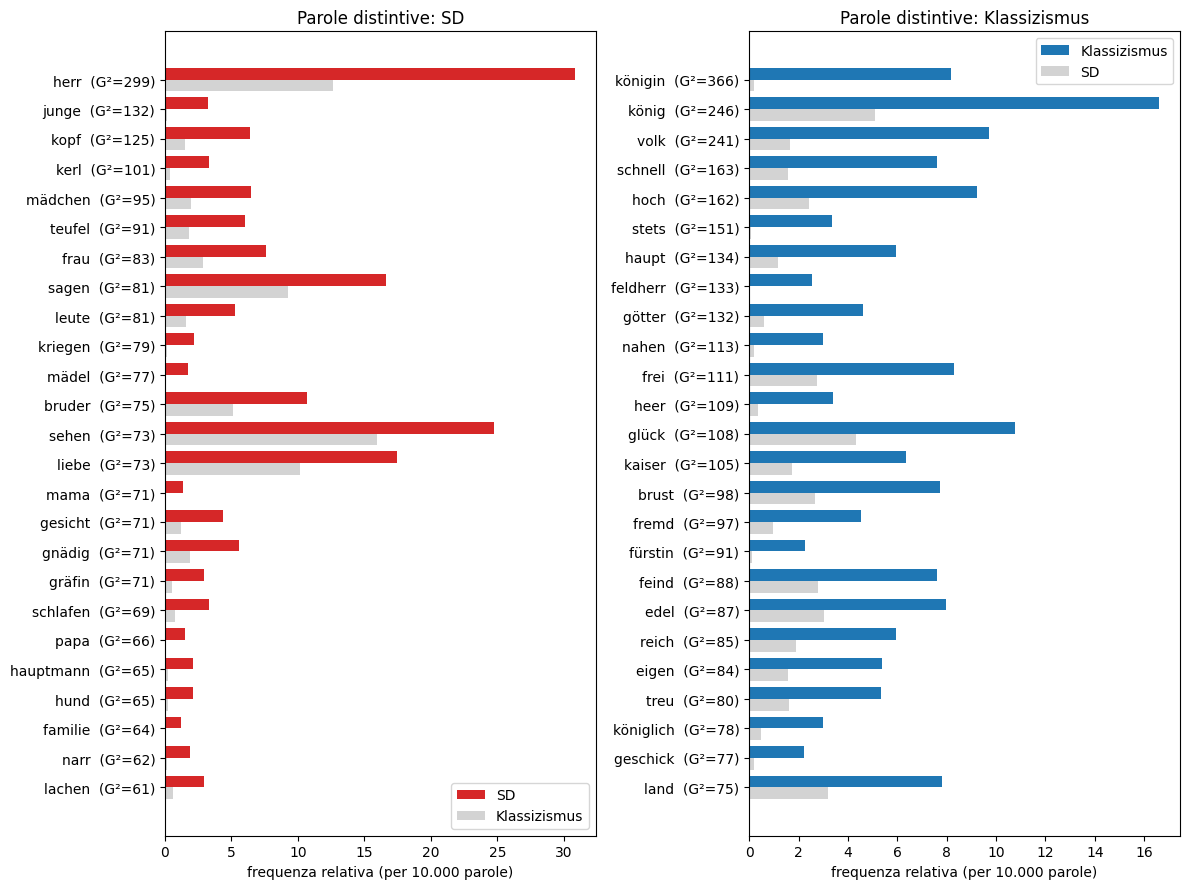

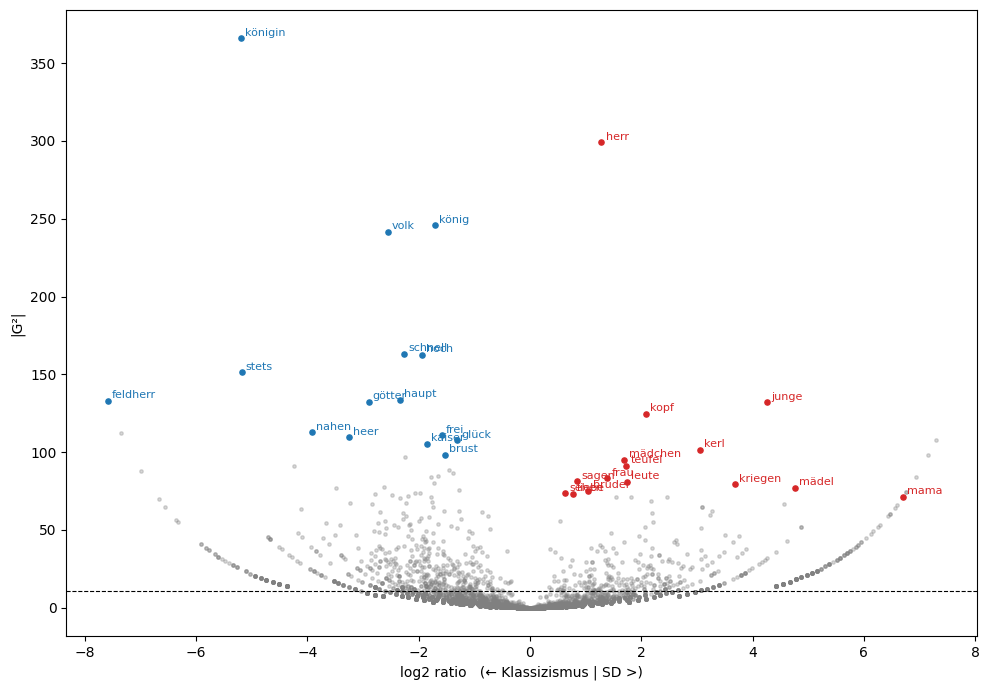

In [10]:
# Colore di ogni classe: rosso SD, blu Klassizismus
COLORI = {"SD": "tab:red", "Klassizismus": "tab:blue"}
ALTRA = {"SD": "Klassizismus", "Klassizismus": "SD"}


def barre_distintive(ax, c, tabella, n=25):
    """Barre affiancate: frequenza della parola nella sua classe (colore) e nell'altra (grigio)."""
    top = tabella.head(n)
    y = np.arange(len(top))[::-1]                      # la parola con G² più alto sta in cima
    ax.barh(y + 0.2, top[f"f_{c} x10k"], height=0.4, color=COLORI[c], label=c)
    ax.barh(y - 0.2, top[f"f_{ALTRA[c]} x10k"], height=0.4, color="lightgray", label=ALTRA[c])
    ax.set_yticks(y)
    ax.set_yticklabels([f"{w}  (G²={abs(g):.0f})" for w, g in zip(top.index, top["G2"])])
    ax.set_xlabel("frequenza relativa (per 10.000 parole)")
    ax.set_title(f"Parole distintive: {c}")
    ax.legend()


# Primo grafico: un pannello per classe
fig, assi = plt.subplots(1, 2, figsize=(12, 9))
for ax, (c, tabella) in zip(assi, [("SD", distintive_SD), ("Klassizismus", distintive_K)]):
    barre_distintive(ax, c, tabella)
plt.tight_layout()
plt.show()

# Secondo grafico: ogni parola è un punto (x = quanto è grande la differenza, y = quanto è affidabile)
visibili = freq[freq["totale"] >= MIN_COUNT]
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(visibili["log2_ratio"], visibili["G2"].abs(), s=6, alpha=0.3, color="gray")

# Evidenzio e nomino le prime 15 parole distintive di ciascuna classe
for c, tabella in [("SD", distintive_SD.head(15)), ("Klassizismus", distintive_K.head(15))]:
    ax.scatter(tabella["log2_ratio"], tabella["G2"].abs(), s=14, color=COLORI[c])
    for w, riga in tabella.iterrows():
        ax.annotate(w, (riga["log2_ratio"], abs(riga["G2"])), fontsize=8, color=COLORI[c],
                    xytext=(3, 2), textcoords="offset points")

ax.axhline(10.83, ls="--", lw=0.8, color="black")      # soglia per un singolo test (p < 0,001)
ax.set_xlabel("log2 ratio   (← Klassizismus | SD >)")
ax.set_ylabel("|G²|")
plt.tight_layout()
plt.show()

### 6b. Seconda misura: log-odds con prior informativo

G² può essere ingannato dalle parole rare (poche occorrenze possono produrre una differenza apparente solo per caso) e dalle parole molto frequenti (anche una differenza piccola diventa "significativa"). Come controllo usiamo una seconda misura, i **log-odds con prior informativo** (Monroe, Colaresi e Quinn 2008).

**Come funziona.** A ogni parola si aggiungono alcune occorrenze "finte", uguali per i due sottocorpora e proporzionali alla frequenza della parola. Per le parole rare questo riduce molto la differenza; per le parole frequenti quasi per nulla.

**Come si legge.** Ogni parola riceve un punteggio *z*: positivo = più frequente nello SD, negativo = più frequente nel Klassizismus. Più è lontano da zero, più la differenza è affidabile (|z| > 4,8 circa corrisponde alla soglia di Bonferroni).

**A cosa serve.** Se una parola è distintiva sia per G² sia per *z*, il risultato non dipende dalla misura scelta.

In [11]:
ALFA0 = CFG["distintive"]["alfa0"]            # forza del prior
Z_SOGLIA = float(np.sqrt(G2_BONF))            # circa 4,8


def z_log_odds(s, k, n1, n2, alfa0=ALFA0):
    """z dei log-odds con prior informativo (Monroe, Colaresi e Quinn 2008).
    Positivo = più frequente in SD, negativo = in Klassizismus."""
    s, k = np.asarray(s, dtype=float), np.asarray(k, dtype=float)
    alfa = alfa0 * (s + k) / (n1 + n2)        # prior proporzionale alla frequenza complessiva
    lo_1 = np.log((s + alfa) / (n1 + alfa0 - s - alfa))
    lo_2 = np.log((k + alfa) / (n2 + alfa0 - k - alfa))
    return (lo_1 - lo_2) / np.sqrt(1 / (s + alfa) + 1 / (k + alfa))


freq["z_logodds"] = z_log_odds(freq["conteggio_SD"], freq["conteggio_Klassizismus"], n_sd, n_k)

# Controllo incrociato: le parole in cima per G² lo sono anche per log-odds?
for c, tab in [("SD", distintive_SD), ("Klassizismus", distintive_K)]:
    segno = 1 if c == "SD" else -1
    ammesse = freq[(freq[f"conteggio_{c}"] >= MIN_COUNT) & (freq[f"opere_{c}"] >= MIN_OPERE)]
    top_z = set((segno * ammesse["z_logodds"]).nlargest(len(tab)).index)
    print(f"{c}: {len(set(tab.index) & top_z)}/{len(tab)} parole sono in cima per G² e anche per log-odds")
    print("   solo G²:      ", ", ".join(sorted(set(tab.index) - top_z)) or "nessuna")
    print("   solo log-odds:", ", ".join(sorted(top_z - set(tab.index))) or "nessuna")

SD: 36/50 parole sono in cima per G² e anche per log-odds
   solo G²:       adieu, arbeiten, dukat, familie, frauenzimmer, hofmeister, komödie, mama, mädel, papa, sapperment, stund, verlieben, wetter
   solo log-odds: abend, beten, bitten, geben, gedanke, gewiss, haar, küssen, lassen, stecken, tot, vater, verzeihen, weinen
Klassizismus: 42/50 parole sono in cima per G² e anche per log-odds
   solo G²:       feldherr, fürstin, geschick, gleich, hold, jungfrau, senden, stets
   solo log-odds: erscheinen, fassen, freund, heilig, kraft, retten, wille, zeigen


## 7. Controlli

G² considera il corpus come un unico sacco di parole, ma le parole stanno dentro **opere** (di lunghezze molto diverse) scritte da **autori**. I controlli di questa sezione e della prossima verificano che le parole distintive non dipendano da una singola opera o da un singolo autore.

Prepariamo le parole da controllare (`candidate`) e il segno atteso: +1 se la parola è tipica dello SD, −1 se della Klassizismus.

In [12]:
# 'candidate' = elenco unico delle parole da controllare: le distintive dello SD seguite da quelle della Klassizismus.
candidate = list(distintive_SD.index) + list(distintive_K.index)       # le parole da controllare
# Per ogni candidata, in quale colonna della matrice X si trova (serve per estrarre i suoi conteggi).
posizione = freq.index.get_indexer(candidate)                          # dove stanno nelle colonne di X
# Per ogni candidata il segno che mi aspetto: +1 se tipica dello SD, −1 se della Klassizismus.
segno_atteso = np.array([1] * len(distintive_SD) + [-1] * len(distintive_K))   # +1 = SD, -1 = Klassizismus


controlli = freq.loc[candidate, ["G2", "log2_ratio", "z_logodds"]].copy()
controlli.insert(0, "classe", np.where(segno_atteso == 1, "SD", "Klassizismus"))
# Colonna vero/falso: G² supera la soglia di Bonferroni?
controlli["G2 > Bonferroni"] = controlli["G2"].abs() > G2_BONF
# Dico quante parole controllo, e quante per classe.
print(f"{len(candidate)} parole da controllare ({len(distintive_SD)} SD + {len(distintive_K)} Klassizismus)")

100 parole da controllare (50 SD + 50 Klassizismus)


### 7a. Controllo per opera, e pesi uguali per opera

**Test di Mann-Whitney.** Per ogni parola calcoliamo la frequenza **in ciascun dramma** (per 10.000 parole di quel dramma) e confrontiamo le opere SD con le opere Klassizismus. Ogni opera pesa uguale, lunga o corta.
- **r**: grandezza dell'effetto (+1 = tutte le opere SD sopra tutte le Klassizismus; −1 = il contrario; 0 = nessuna differenza).
- **q**: p-value corretto per i confronti multipli (Benjamini-Hochberg).

Una parola **regge per opera** se q < 0,05 e r ha il segno atteso.

**Pesi uguali per opera.** G² somma tutte le parole di una classe: un dramma lungo come *Wallenstein* (circa 19.000 parole) pesa più di uno breve. Qui calcoliamo invece la **media delle frequenze delle singole opere**, in cui ogni opera pesa uguale, e il log₂ ratio tra le due medie. Una parola **concorda a pesi uguali** se la differenza ha il segno atteso e almeno la grandezza `MIN_LOG2`. (Aggiungiamo `pseudo_pesi_uguali` per 10.000 parole alle medie per evitare divisioni per zero; valore nella cella di configurazione.)

In [13]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# Lemmi con abbastanza occorrenze; frequenze per 10.000 parole di ogni opera
da_testare = (freq["totale"] >= MIN_COUNT).to_numpy()
frequenza_opera = X / parole_opera[:, None] * 1e4
F_sd = frequenza_opera[opera_sd][:, da_testare]
F_k  = frequenza_opera[~opera_sd][:, da_testare]

# Mann-Whitney tra opere SD e Klassizismus, con correzione Benjamini-Hochberg
U, p = mannwhitneyu(F_sd, F_k, alternative="two-sided", axis=0)
q = multipletests(np.nan_to_num(p, nan=1.0), method="fdr_bh")[1]
r = 2 * U / (len(F_sd) * len(F_k)) - 1          # +1 = tutte le opere SD sopra tutte le Klassizismus
per_opera = pd.DataFrame({"r_opere": r, "q_opere": q}, index=freq.index[da_testare])

# Controllo 1: regge per opera (q < 0,05 e segno atteso)
controlli[["r_opere", "q_opere"]] = per_opera.loc[candidate].to_numpy()
controlli["regge per opera"] = (controlli["q_opere"] < 0.05) & (segno_atteso * controlli["r_opere"] > 0)

# Controllo 2: pesi uguali per opera (media delle frequenze per opera, per classe)
eps = CFG["distintive"]["pseudo_pesi_uguali"]
media_sd = frequenza_opera[opera_sd].mean(0)[posizione]
media_k  = frequenza_opera[~opera_sd].mean(0)[posizione]
controlli["log2 pesi uguali"] = np.log2((media_sd + eps) / (media_k + eps))
controlli["concorda a pesi uguali"] = segno_atteso * controlli["log2 pesi uguali"] >= MIN_LOG2

# Riepilogo per classe
for c in classi:
    t = controlli[controlli["classe"] == c]
    print(f"{c}: {t['G2 > Bonferroni'].sum()}/{len(t)} sopra Bonferroni, "
          f"{t['regge per opera'].sum()}/{len(t)} reggono per opera, "
          f"{t['concorda a pesi uguali'].sum()}/{len(t)} concordano a pesi uguali")
    for col, etichetta in [("regge per opera", "NON reggono per opera"),
                           ("concorda a pesi uguali", "NON concordano a pesi uguali")]:
        print(f"   {etichetta}:", ", ".join(t.index[~t[col]]) or "nessuna")

SD: 50/50 sopra Bonferroni, 33/50 reggono per opera, 49/50 concordano a pesi uguali
   NON reggono per opera: frau, bruder, liebe, mama, gnädig, gräfin, papa, hauptmann, hofmeister, brav, brand, verlieben, schreiben, ritter, sapperment, dukat, jung
   NON concordano a pesi uguali: liebe
Klassizismus: 50/50 sopra Bonferroni, 40/50 reggono per opera, 50/50 concordano a pesi uguali
   NON reggono per opera: königin, könig, götter, kaiser, fürstin, feind, königlich, land, jungfrau, wort
   NON concordano a pesi uguali: nessuna


**Grafico per opera.** Ogni punto è un'opera, la linea nera è la mediana. Una parola solida ha le due nuvole separate; una fragile ha quasi tutti i punti a zero e pochi valori molto alti.

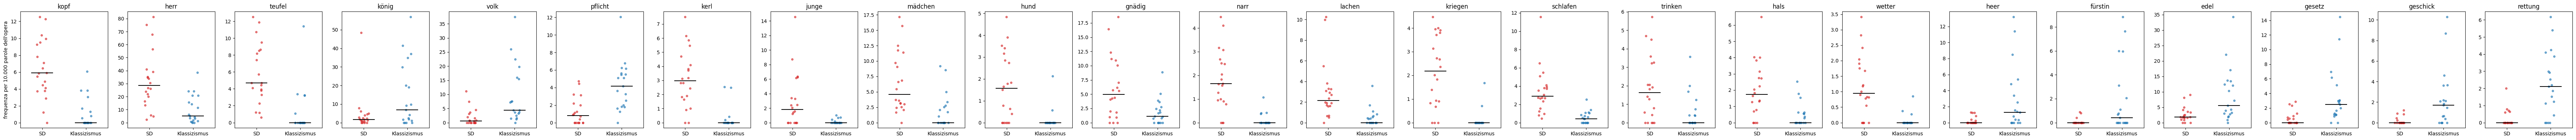

In [14]:
def mostra_per_opera(parole):
    """Un punto per opera (rosso SD, blu Klassizismus) e linea nera sulla mediana."""
    parole = [w for w in parole if w in freq.index and da_testare[freq.index.get_loc(w)]]
    if not parole:
        print("Nessuna parola con abbastanza occorrenze")
        return

    rng_g = np.random.default_rng(0)   # sfalsa i punti in orizzontale (seed fisso = grafico ripetibile)
    gruppi = [(opera_sd, "tab:red"), (~opera_sd, "tab:blue")]
    fig, assi = plt.subplots(1, len(parole), figsize=(3 * len(parole), 4), squeeze=False)

    for ax, w in zip(assi[0], parole):
        valori = frequenza_opera[:, freq.index.get_loc(w)]
        for i, (maschera, colore) in enumerate(gruppi):
            v = valori[maschera]
            ax.scatter(i + rng_g.uniform(-0.12, 0.12, len(v)), v, s=14, alpha=0.6, color=colore)
            ax.hlines(np.median(v), i - 0.25, i + 0.25, color="black")
        ax.set(title=w, xticks=[0, 1], xticklabels=["SD", "Klassizismus"], xlim=(-0.5, 1.5))

    assi[0][0].set_ylabel("frequenza per 10.000 parole dell'opera")
    plt.tight_layout()
    plt.show()


mostra_per_opera(["kopf", "herr", "teufel", "könig", "volk", "pflicht", "kerl", "junge",
                  "mädchen", "hund", "gnädig", "narr", "lachen", "kriegen", "schlafen",
                  "trinken", "hals", "wetter", "heer", "fürstin", "edel", "gesetz",
                  "geschick", "rettung"])

### 7b. Controllo a parità di autore

Goethe e Schiller compaiono **in entrambe le classi**: confrontando il Goethe SD con il Goethe della Klassizismus (e lo stesso per Schiller) l'autore resta lo stesso e cambia il periodo (e con esso, di solito, anche la forma, i temi e l'edizione). Una parola tipica della corrente deve andare nella stessa direzione anche dentro ciascun autore. Il segno è giudicato solo se l'autore usa la parola almeno `MIN_OCC_AUTORE` volte in tutto.

L'autore è ricavato dal nome del file (la parte prima del primo trattino); i casi particolari (*Schlegel*, *Maler Müller*) sono sistemati a mano in `AUTORE_MANUALE`.

In [15]:
MIN_OCC_AUTORE = CFG["distintive"]["min_occ_autore"]   # occorrenze minime per giudicare il segno in un autore

# Autore di ogni opera: dal dizionario manuale, altrimenti la parte del nome prima del primo trattino
autore_di = {o: CFG["corpus"]["autore_manuale"].get(o, o.split("-")[0]) for o in opere}
autore_arr = np.array([autore_di[o] for o in opere])

# Autori presenti in entrambe le classi: gli unici per confrontare la stessa mano in due periodi
tabella_ac = pd.crosstab(pd.Series(autore_arr, name="autore"),
                         pd.Series(np.where(opera_sd, "SD", "Klassizismus"), name="classe"))
autori_condivisi = sorted(tabella_ac.index[(tabella_ac > 0).all(axis=1)])
print("Autori presenti in entrambe le classi:", ", ".join(autori_condivisi))
print("Opere per autore e classe:")
print(tabella_ac.to_string())

# Segno confermato dentro ogni autore condiviso?
segni_ok = pd.DataFrame(index=candidate)
for aut in autori_condivisi:
    di_aut = autore_arr == aut
    cnt_sd, cnt_k = (X[di_aut & m].sum(0)[posizione] for m in (opera_sd, ~opera_sd))
    tok_sd, tok_k = (parole_opera[di_aut & m].sum() for m in (opera_sd, ~opera_sd))

    log2_autore = np.log2(((cnt_sd + 0.5) / tok_sd) / ((cnt_k + 0.5) / tok_k))
    giudicabile = (cnt_sd + cnt_k) >= MIN_OCC_AUTORE   # se l'autore usa poco la parola, non penalizzo

    controlli[f"log2 {aut}"] = np.where(giudicabile, log2_autore, np.nan)
    segni_ok[aut] = (np.sign(log2_autore) * segno_atteso > 0) | ~giudicabile

controlli["concorda in ogni autore"] = segni_ok.all(axis=1)

for c in classi:
    t = controlli[controlli["classe"] == c]
    print(f"\n{c}: {t['concorda in ogni autore'].sum()}/{len(t)} concordano dentro {' e '.join(autori_condivisi)}")
    print("   si invertono in almeno un autore:", ", ".join(t.index[~t["concorda in ogni autore"]]) or "nessuna")

Autori presenti in entrambe le classi: goethe, schiller
Opere per autore e classe:
classe         Klassizismus  SD
autore                         
collin                    2   0
goethe                    6   4
klinger                   0   5
leisewitz                 0   1
lenz                      0   4
maler-mueller             0   1
schiller                  6   3
schlegel-aw               1   0
schlegel-f                1   0
seume                     1   0
wagner                    0   2
wieland                   1   0
wolzogen                  1   0

SD: 47/50 concordano dentro goethe e schiller
   si invertono in almeno un autore: wissen, brav, ritter

Klassizismus: 45/50 concordano dentro goethe e schiller
   si invertono in almeno un autore: königin, kaiser, feind, reich, land


### 7c. Quanto sono confusi tra loro classe, autori, periodo e forma?

I controlli precedenti escludono che una parola dipenda da una sola opera o da un solo autore. Non possono però escludere che la differenza tra i due sottocorpora dipenda da **ciò che li accompagna**: il periodo, gli autori (alcuni compaiono in una sola classe), la forma (verso o prosa). Questa cella lo misura, in modo che il confondimento sia **dichiarato e quantificato** invece che taciuto.

La cella riassume per classe quota di versi e autori, e quanta parte delle parole viene da autori presenti in una sola classe.

## 8. Controlli di robustezza

I controlli di base dicono che le parole distintive non dipendono da *una* opera. Questa sezione chiede se dipendono da **come è fatto il corpus** (quali autori ci sono, quanto pesano) e da **come sono scelti i parametri**.

### 8a. Quanto distintive sono le parole di una divisione casuale?

Dividendo i drammi in due gruppi qualsiasi, G² trova **sempre** qualche parola distintiva. Il test di permutazione costruisce il termine di paragone: si rimescolano le etichette SD/Klassizismus e si contano le parole distintive della divisione casuale (stessi filtri della sezione 6, con Bonferroni). Il p-value è la quota di divisioni casuali che producono almeno tante parole quante la divisione reale. Con `N_PERM` = 1000 il valore più basso possibile è 1/1001 ≈ 0,001.

Due modalità:

- **opere**: si rimescolano le etichette tra singole opere;
- **autori** (8b): si rimescolano blocchi **autore × classe**. Le opere dello stesso autore nello stesso periodo restano insieme.

In [17]:
def conta(in_sd):
    """Numero di parole distintive (con Bonferroni) per una data divisione delle opere."""
    ok_sd, ok_k, _, _ = parole_distintive(X, in_sd, ~in_sd)
    return int(ok_sd.sum() + ok_k.sum())

reali = conta(opera_sd)
print(f"Divisione reale SD/Klassizismus: {reali} parole distintive (con Bonferroni)")

Divisione reale SD/Klassizismus: 366 parole distintive (con Bonferroni)


### 8b. Permutazione per blocchi autore × classe

Ogni blocco è un insieme di opere dello stesso autore nella stessa classe (per esempio «klinger|SD», «goethe|Klassizismus»). Si rimescolano le etichette dei **blocchi**, mantenendo il numero di blocchi SD e Klassizismus: lo stile personale di un autore non può così gonfiare il risultato. Il test è più severo del precedente.

15 blocchi autore × classe (7 SD, 8 Klassizismus)
[autori] divisioni casuali: media 95, 95° percentile 170, massimo 346 >  p = 0.0010
Divisione reale: 366 parole distintive.


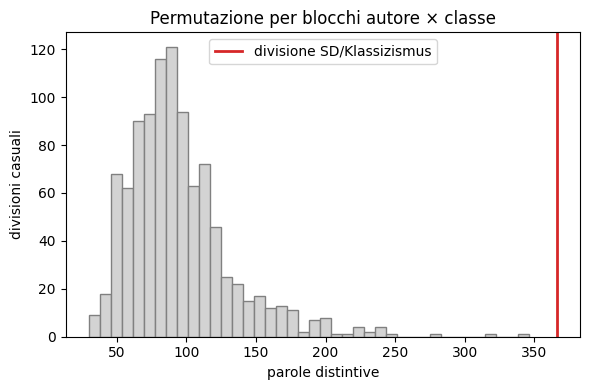

In [18]:
rng = np.random.default_rng([SEED, 2])

blocco = np.array([f"{autore_di[o]}|{classe_di[o]}" for o in opere])   # autore × classe
blocchi = np.unique(blocco)
blocchi_sd = np.array([b.endswith("|SD") for b in blocchi])
print(f"{len(blocchi)} blocchi autore × classe ({blocchi_sd.sum()} SD, {(~blocchi_sd).sum()} Klassizismus)")

def rimescola_blocchi():
    """Rimescola le etichette tra blocchi, mantenendo il numero di blocchi SD e Klassizismus."""
    etichette = dict(zip(blocchi, rng.permutation(blocchi_sd)))
    return np.array([etichette[b] for b in blocco])

casuali_autori = np.array([conta(rimescola_blocchi()) for _ in range(N_PERM)])
p_autori = (np.sum(casuali_autori >= reali) + 1) / (N_PERM + 1)
print(f"[autori] divisioni casuali: media {casuali_autori.mean():.0f}, "
      f"95° percentile {np.percentile(casuali_autori, 95):.0f}, "
      f"massimo {casuali_autori.max()} >  p = {p_autori:.4f}")
print(f"Divisione reale: {reali} parole distintive.")

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(casuali_autori, bins=40, color="lightgray", edgecolor="gray")
ax.axvline(reali, color="tab:red", lw=2, label="divisione SD/Klassizismus")
ax.set(title="Permutazione per blocchi autore × classe",
       xlabel="parole distintive", ylabel="divisioni casuali")
ax.legend()
plt.tight_layout()
plt.show()

### 8c. Leave-one-author-out: togliere un autore alla volta

Ricalcoliamo le parole distintive togliendo **tutte le opere di un autore** (in entrambe le classi) e ripetiamo per ogni autore. Una parola è **stabile** se resta distintiva qualunque autore venga tolto. Per le parole che cadono, la colonna `cade senza` dice quale autore (o autori) la regge.

In [19]:
def candidate_ancora_distintive(maschera_opere, **parametri):
    """Per ogni parola candidata: è ancora distintiva (nella sua classe) usando solo le opere della maschera?"""
    ok_sd, ok_k, _, _ = parole_distintive(X, opera_sd & maschera_opere, ~opera_sd & maschera_opere, **parametri)
    return np.where(segno_atteso > 0, ok_sd[posizione], ok_k[posizione])

# Leave-one-author-out: per ogni autore tolgo tutte le sue opere
autori_tutti = sorted(set(autore_arr))
LOAO = pd.DataFrame({a: candidate_ancora_distintive(autore_arr != a) for a in autori_tutti}, index=candidate)
ok_con_tutti = pd.Series(candidate_ancora_distintive(np.ones(len(opere), bool)), index=candidate)

# Stabile = distintiva con tutti gli autori E senza ciascuno di essi
controlli["stabile senza ogni autore"] = ok_con_tutti & LOAO.all(axis=1)
controlli["cade senza"] = [
    ", ".join(LOAO.columns[~LOAO.loc[w]]) if ok_con_tutti[w]
    else "(già non distintiva con tutti gli autori)"
    for w in candidate]

for c in classi:
    t = controlli[controlli["classe"] == c]
    print(f"{c}: {t['stabile senza ogni autore'].sum()}/{len(t)} stabili togliendo un autore alla volta")
    instabili = t[~t["stabile senza ogni autore"]]
    print("   instabili:", "; ".join(f"{w} (cade senza {r})" for w, r in instabili["cade senza"].items()) or "nessuna")

print("\nParole che cadono togliendo ciascun autore:")
print((~LOAO)[ok_con_tutti].sum().sort_values(ascending=False).to_string())

SD: 35/50 stabili togliendo un autore alla volta
   instabili: sehen (cade senza klinger); liebe (cade senza klinger); gräfin (cade senza maler-mueller); papa (cade senza lenz); hauptmann (cade senza schiller); wissen (cade senza lenz, wagner); hofmeister (cade senza lenz); brand (cade senza klinger); hals (cade senza schiller); bekommen (cade senza lenz); schreiben (cade senza lenz); ritter (cade senza goethe, maler-mueller); sapperment (cade senza wagner); dukat (cade senza lenz); jung (cade senza lenz, schiller)
Klassizismus: 41/50 stabili togliendo un autore alla volta
   instabili: königin (cade senza schiller); kaiser (cade senza schiller); feind (cade senza schiller); eigen (cade senza schiller); königlich (cade senza schiller); land (cade senza schiller); jungfrau (cade senza schiller); scheinen (cade senza goethe); hold (cade senza goethe)

Parole che cadono togliendo ciascun autore:
schiller         10
lenz              7
goethe            3
klinger           3
maler-mueller 

## 10. Campi semantici e posizione dei drammi

### 10a. Raggruppare le parole distintive per significato

Qui raggruppiamo le parole distintive in **campi semantici** in modo automatico:

1. di ogni parola distintiva si prende il **vettore** del modello grande (un elenco di 300 numeri che codifica il significato: parole simili hanno vettori simili);
2. l'algoritmo **K-means** raggruppa le parole in `N_CAMPI` gruppi di vettori vicini;
3. per ogni gruppo si stampano le parole e si misura **quanto pesa nei drammi SD e nei drammi Klassizismus** (per 10.000 parole), con il test di Mann-Whitney sulle opere.

I gruppi sono costruiti sulle sole parole distintive, quindi tendono a separarsi per sottocorpus (il test sui campi è quindi in parte circolare: i p-value vanno letti solo come descrizione, non come prova); a noi interessa vedere **quali temi** compaiono e se ci sono gruppi misti. **Dare il nome ai campi spetta a te**: guarda le parole di ciascuno. I campi dipendono dal numero scelto: prova anche `N_CAMPI` = 5 o 12.

Per avere abbastanza parole si usano tutte le parole distintive della sezione 6 fino a un massimo di `N_PAROLE_CAMPI`.

In [20]:
# carica il modello grande `de_core_news_lg`, che ha i vettori delle parole;
# per ogni lemma di `freq` cerca il vettore, provando la forma com'è, con l'iniziale maiuscola (i nomi tedeschi) e in minuscolo;
#salva tutto in `risultato_conf = {"vettori": ...}`, cioè il nome e la struttura che la 10a si aspetta (`risultato_conf["vettori"]`).
import spacy
vettori = {}
try:
    _vocab = spacy.load(MODELLO_CONFRONTO, exclude=["tok2vec", "tagger", "parser", "ner", "lemmatizer", "attribute_ruler", "senter"]).vocab
    for w in freq.index:
        for forma in (w, w.capitalize(), w.lower()):
            if _vocab.has_vector(forma):
                vettori[w] = _vocab.get_vector(forma)
                break
except OSError:
    print(f"Modello {MODELLO_CONFRONTO} non installato: python -m spacy download {MODELLO_CONFRONTO}")
risultato_conf = {"vettori": vettori}
print(f"{len(vettori):,} lemmi su {len(freq):,} hanno un vettore")

18,051 lemmi su 33,579 hanno un vettore


In [21]:
import spacy
from sklearn.cluster import KMeans

N_PAROLE_CAMPI = CFG["campi"]["n_parole_campi"]

# 1. Parole distintive (Bonferroni), le prime N per |G²|
ok_sd, ok_k, g, _ = parole_distintive(X, opera_sd, ~opera_sd)
scelte = np.where(ok_sd | ok_k)[0]
scelte = scelte[np.argsort(-np.abs(g[scelte]))][:N_PAROLE_CAMPI]

# 2. Vettori dal modello grande (se manca, la sezione viene saltata)
campo_di = {}
try:
    vocab = spacy.load(MODELLO_CONFRONTO, exclude=["tok2vec", "tagger", "parser", "ner",
                                                   "lemmatizer", "attribute_ruler", "senter"]).vocab
except OSError:
    vocab = None
    print(f"Modello {MODELLO_CONFRONTO} non installato: python -m spacy download {MODELLO_CONFRONTO}")

if vocab is not None:
    parole_campi, vettori = [], []
    for i in scelte:
        w = freq.index[i]
        for forma in (w, w.capitalize()):
            if vocab.has_vector(forma):
                parole_campi.append(w)
                vettori.append(vocab.get_vector(forma))
                break

    # 3. KMeans su vettori di lunghezza 1
    V = np.array(vettori)
    V = V / np.linalg.norm(V, axis=1, keepdims=True)
    etichette = KMeans(n_clusters=N_CAMPI, n_init=10, random_state=SEED).fit_predict(V)
    campo_di = dict(zip(parole_campi, etichette))
    print(f"{len(parole_campi)} parole raggruppate in {N_CAMPI} campi\n")

    # 4. Peso di ogni campo in ogni opera e confronto SD / Klassizismus
    righe = []
    F_campi = np.zeros((len(opere), N_CAMPI))
    for c in range(N_CAMPI):
        membri = [w for w in parole_campi if campo_di[w] == c]
        idx = freq.index.get_indexer(membri)
        F_campi[:, c] = X[:, idx].sum(1) / parole_opera * 1e4      # occorrenze per 10.000 parole
        n_sd_w = sum(freq.loc[w, "G2"] > 0 for w in membri)
        U, p = mannwhitneyu(F_campi[opera_sd, c], F_campi[~opera_sd, c], alternative="two-sided")
        righe.append({"campo": c, "parole SD": n_sd_w, "parole Klassizismus": len(membri) - n_sd_w,
                      "x10k SD (mediana)": np.median(F_campi[opera_sd, c]),
                      "x10k Klassizismus (mediana)": np.median(F_campi[~opera_sd, c]),
                      "r_opere": 2 * U / (opera_sd.sum() * (~opera_sd).sum()) - 1, "p": p})
        ordinati = sorted(membri, key=lambda w: -abs(freq.loc[w, "G2"]))
        print(f"CAMPO {c}  ({n_sd_w} SD, {len(membri) - n_sd_w} Klassizismus)")
        print("   ", ", ".join(f"{w}{'*' if freq.loc[w, 'G2'] > 0 else ''}" for w in ordinati[:25]))
    print("\n(* = parola distintiva dello SD; senza asterisco = Klassizismus)\n")

    # 5. Tabella dei campi con p corretti (Benjamini-Hochberg)
    campi_tab = pd.DataFrame(righe).set_index("campo")
    campi_tab["q"] = multipletests(campi_tab["p"], method="fdr_bh")[1]
    print(campi_tab.round(3).to_string())

292 parole raggruppate in 8 campi

CAMPO 0  (26 SD, 8 Klassizismus)
    kopf*, kerl*, brust, mädchen*, frau*, leute*, mädel*, bruder*, mama*, papa*, hund*, jungfrau, schmerz, freund, hals*, lust, stund*, kranz, maul*, haar*, hure*, busen, monat*, esel*, drüber*
CAMPO 1  (4 SD, 37 Klassizismus)
    vertrauen, senden, sprechen, erscheinen, lösen, zeigen, ergreifen, wirken, vereinen, bedürfen, beschützen, arbeiten*, vollbringen, fassen, verbergen, sorge, bekommen*, bewegen, dringen, erfüllen, fordern, tragen, drängen, streben, fügen
CAMPO 2  (20 SD, 13 Klassizismus)
    sagen*, kriegen*, sehen*, schlafen*, folgen, lachen*, wissen*, ehren, schrecken, beglücken, laufen*, verkünden, schreiben*, lesen*, küssen*, empfangen, horchen, essen*, bitten*, beten*, beginnen, üben, leuchten, ankommen*, ansehen*
CAMPO 3  (5 SD, 19 Klassizismus)
    hoch, nahen, reich, liebe*, teuer, herum*, retten, mächtig, heilig, furchtbar, verehren, fern, verlieben*, verhasst, versöhnen, heil, verschmähen, verzeihen*

### 10b. Quanto pesa ogni campo in ogni dramma

Il grafico è una mappa: ogni riga è un dramma (in alto lo SD, in basso la Klassizismus), ogni colonna un campo. Il colore dice se il campo è **più o meno presente della media** (in rosso: più presente; in blu: meno). Si vede a colpo d'occhio quali drammi si comportano da «tipici» della loro classe e quali «di confine».

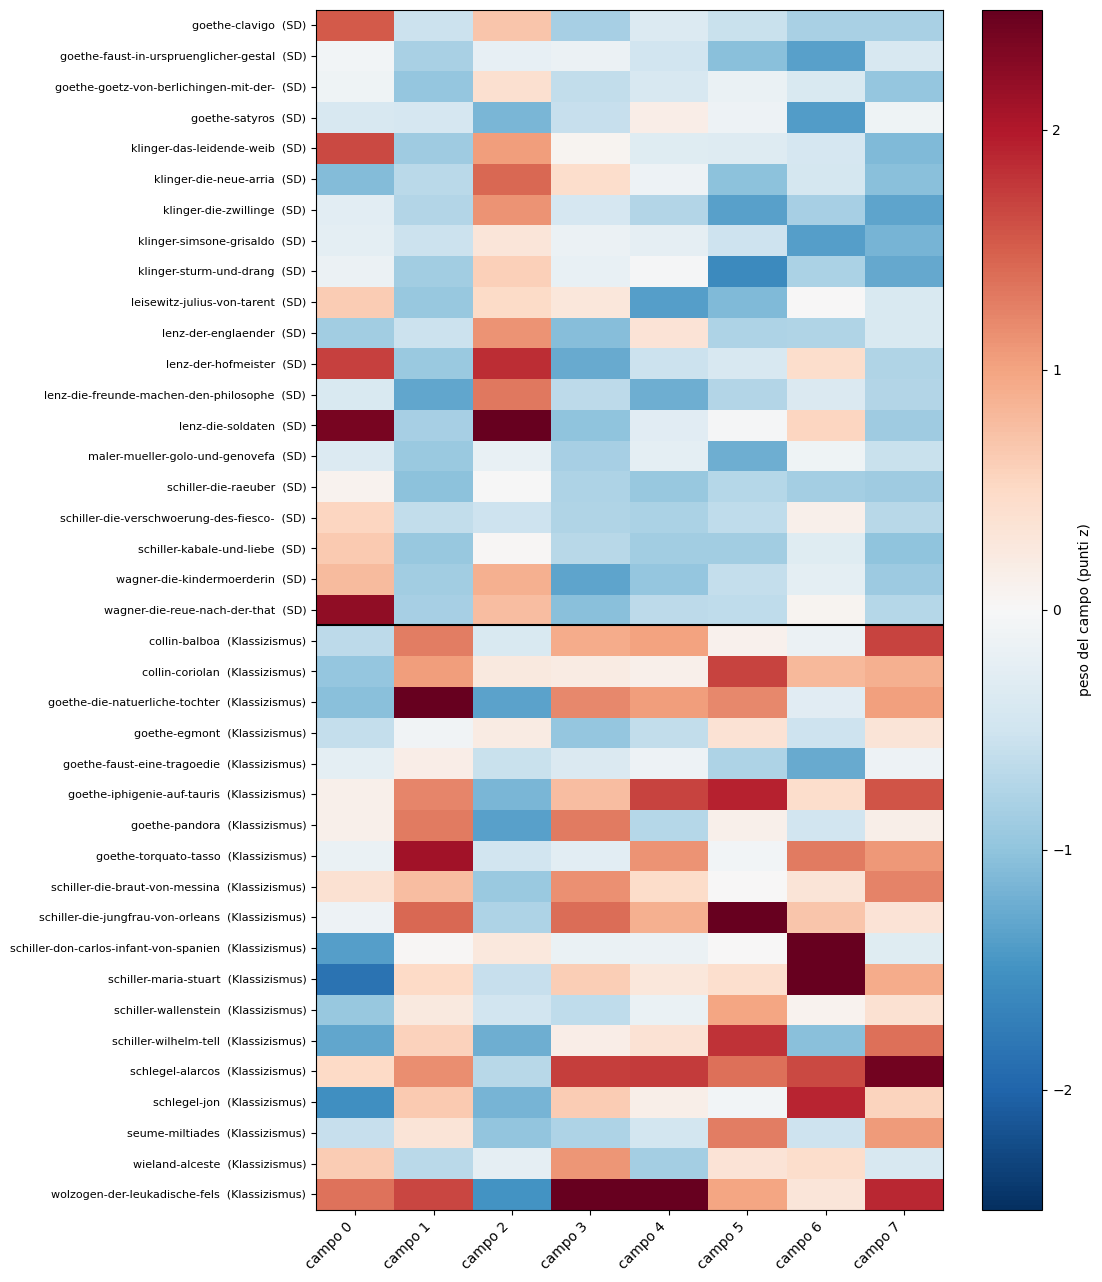

In [22]:
if campo_di:
    # Peso di ogni campo in punti z (media 0, dev. standard 1), così i campi sono confrontabili
    Z = (F_campi - F_campi.mean(0)) / F_campi.std(0)

    # Righe: prima le opere SD, poi le Klassizismus, in ordine alfabetico
    ordine = np.lexsort((np.array(opere), ~opera_sd))

    fig, ax = plt.subplots(figsize=(0.9 * N_CAMPI + 4, 0.28 * len(opere) + 2))
    im = ax.imshow(Z[ordine], cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")   # rosso = sopra la media, blu = sotto

    ax.set_xticks(range(N_CAMPI))
    ax.set_xticklabels([f"campo {c}" for c in range(N_CAMPI)], rotation=45, ha="right")
    ax.set_yticks(range(len(opere)))
    ax.set_yticklabels([f"{opere[i][:38]}  ({classe_di[opere[i]]})" for i in ordine], fontsize=8)

    ax.axhline(opera_sd.sum() - 0.5, color="black", lw=1.5)   # separa SD da Klassizismus
    plt.colorbar(im, label="peso del campo (punti z)")
    plt.tight_layout()
    plt.show()

### 10c. Posizione di ogni dramma sull'asse lessicale, con leave-one-author-out e AUC

Ogni dramma riceve un **punteggio lessicale**: la somma, parola per parola, della sua frequenza (sul totale delle parole del testo) moltiplicata per il log₂ ratio della parola (positivo = SD, negativo = Klassizismus). Usiamo solo parole con G² sopra Bonferroni.

Il lessico con cui si valuta un dramma è sempre ricalcolato **senza** quel dramma, in due modi:

- **leave-one-work-out** (`posizione_loo_opera`): si toglie solo l'opera valutata. Resta però il resto dell'opera dello stesso autore (Klinger e Lenz hanno 5 e 4 opere): lo stile d'autore entra nel lessico e il punteggio è **ottimistico**;
- **leave-one-author-out** (`posizione_loao`): si tolgono **tutte** le opere dell'autore dell'opera valutata (in entrambe le classi). È la misura più severa ed è quella riportata come `posizione`.

Il punteggio viene ridotto a una scala semplice: **0 = come la media dei drammi Klassizismus, 1 = come la media dei drammi SD**. Per valutare quanto l'asse separi davvero i due sottocorpora si calcola l'**AUC** (probabilità che un dramma SD abbia un punteggio più alto di uno Klassizismus; 0,5 = caso, 1 = separazione perfetta) con un intervallo di confidenza per **bootstrap sugli autori** (si ricampionano gli autori, non le opere, perché le opere dello stesso autore non sono indipendenti), e l'AUC dentro ciascun autore presente in entrambe le classi.

Nota di lettura: anche un AUC alto con LOAO dice che il lessico distingue i due sottocorpora, non che la causa sia la «corrente»: periodo e forma restano confusi con la classe (sezione 7c).

                                                  AUC IC95 inf IC95 sup accuratezza (soglia 0,5)
valutazione                                                                                     
leave-one-work-out (ottimistico)                0.995    0.968    1.000                    0.923
leave-one-author-out                            0.984    0.958    1.000                    0.923
dentro goethe (LOAO, 4 SD vs 6 Klassizismus)    0.958        –        –                        –
dentro schiller (LOAO, 3 SD vs 6 Klassizismus)  1.000        –        –                        –

Posizione (LOAO): 0 = come la media dei drammi Klassizismus, 1 = come la media dei drammi SD
              count  mean   std   min   max
classe                                     
Klassizismus   19.0  -0.0  0.42 -0.92  0.86
SD             20.0   1.0  0.27  0.60  1.48

Drammi SD più vicini alla Klassizismus: klinger-simsone-grisaldo (0.60), goethe-satyros (0.62), klinger-sturm-und-drang (0.66), klinger-die-neue-ar

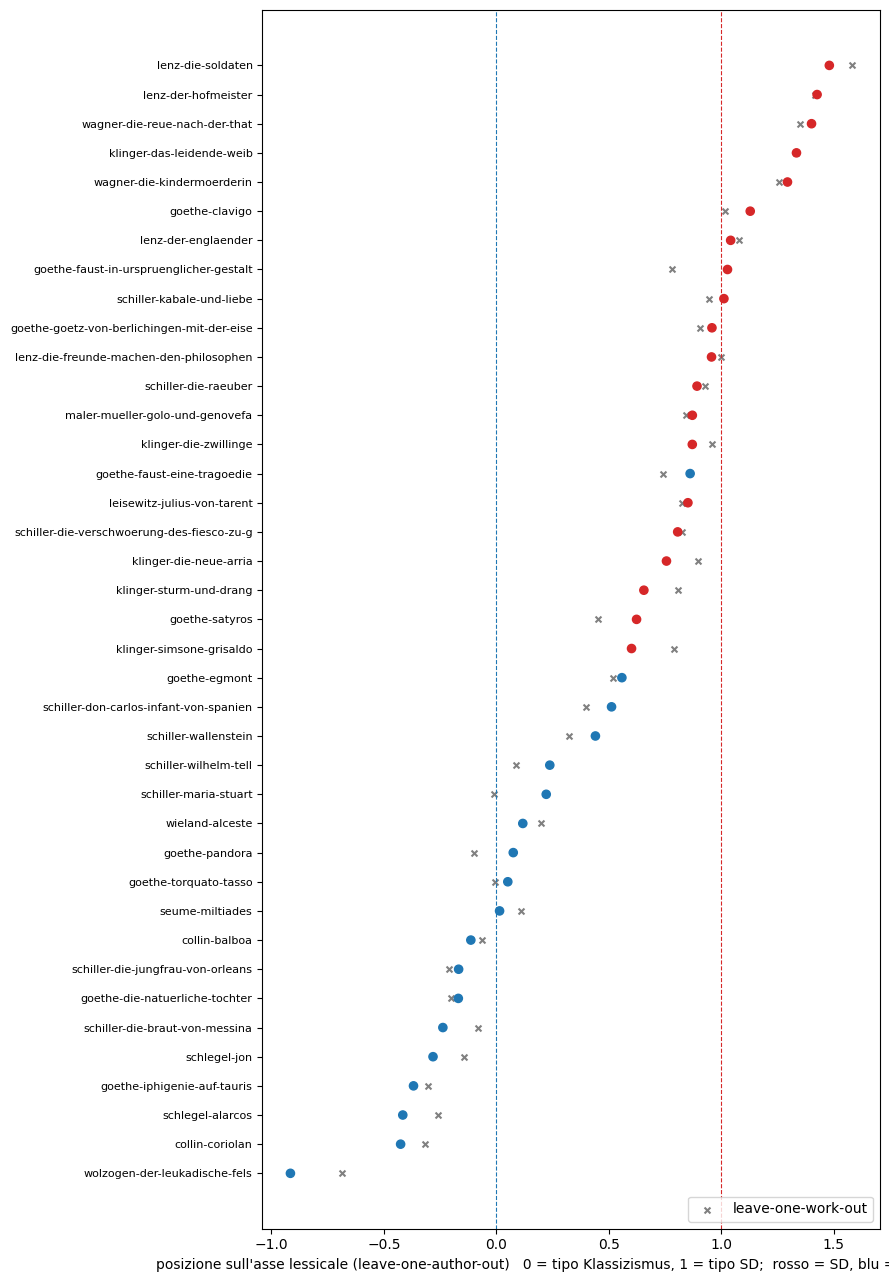

In [23]:
from scipy.stats import mannwhitneyu

Xrel = X / parole_opera[:, None]      # frequenza relativa sul totale delle parole del testo


def punteggi_senza(gruppi):
    """Punteggio di ogni opera calcolato con un lessico imparato SENZA il suo gruppo
    (una sola opera, oppure tutte le opere di un autore). Positivo = lessico SD, negativo = Klassizismus."""
    punti = np.zeros(len(opere))
    for gr in np.unique(gruppi):
        fuori = gruppi == gr                 # opere da valutare
        resto = ~fuori                       # opere da cui imparo il lessico
        s, k = X[resto & opera_sd].sum(0), X[resto & ~opera_sd].sum(0)
        n1, n2 = parole_opera[resto & opera_sd].sum(), parole_opera[resto & ~opera_sd].sum()
        g = g2(s, k, n1, n2)
        l2 = np.log2(((s + 0.5) / n1) / ((k + 0.5) / n2))
        # peso = log2 ratio, solo per le parole con abbastanza occorrenze e G² sopra Bonferroni
        pesi = np.where(((s + k) >= MIN_COUNT) & (np.abs(g) > G2_BONF), l2, 0.0)
        punti[fuori] = Xrel[fuori] @ pesi
    return punti


punt_loo = punteggi_senza(np.array(opere))    # leave-one-work-out (ottimistico)
punt_loao = punteggi_senza(autore_arr)        # leave-one-author-out (il più severo)


def su_scala(p):
    """0 = media delle opere Klassizismus, 1 = media delle opere SD."""
    return (p - p[~opera_sd].mean()) / (p[opera_sd].mean() - p[~opera_sd].mean())


def auc_asse(p, maschera=None):
    """AUC: probabilità che un dramma SD abbia punteggio più alto di uno Klassizismus (0,5 = caso, 1 = separazione perfetta)."""
    m = np.ones(len(p), bool) if maschera is None else maschera
    a, b = p[m & opera_sd], p[m & ~opera_sd]
    if len(a) == 0 or len(b) == 0:
        return np.nan
    return mannwhitneyu(a, b).statistic / (len(a) * len(b))


# Intervallo di confidenza al 95% dell'AUC ricampionando gli AUTORI (le opere dello stesso autore non sono indipendenti)
rng_b = np.random.default_rng([SEED, 4])
autori_unici = np.unique(autore_arr)
idx_per_autore = {a: np.where(autore_arr == a)[0] for a in autori_unici}


def auc_bootstrap_autori(p, B):
    valori = []
    for _ in range(B):
        scelti = rng_b.choice(autori_unici, size=len(autori_unici), replace=True)
        idx = np.concatenate([idx_per_autore[a] for a in scelti])
        a_, b_ = p[idx][opera_sd[idx]], p[idx][~opera_sd[idx]]
        if len(a_) and len(b_):
            valori.append(mannwhitneyu(a_, b_).statistic / (len(a_) * len(b_)))
    return np.percentile(valori, [2.5, 97.5])


N_BOOT = CFG["asse"]["n_bootstrap"]
righe_auc = []
for nome, p in [("leave-one-work-out (ottimistico)", punt_loo), ("leave-one-author-out", punt_loao)]:
    lo, hi = auc_bootstrap_autori(p, N_BOOT)
    righe_auc.append({"valutazione": nome, "AUC": auc_asse(p), "IC95 inf": lo, "IC95 sup": hi,
                      "accuratezza (soglia 0,5)": float(np.mean((su_scala(p) >= 0.5) == opera_sd))})

# Dentro gli autori presenti in entrambe le classi (Goethe e Schiller)
for aut in autori_condivisi:
    m = autore_arr == aut
    righe_auc.append({"valutazione": f"dentro {aut} (LOAO, {int((m & opera_sd).sum())} SD vs {int((m & ~opera_sd).sum())} Klassizismus)",
                      "AUC": auc_asse(punt_loao, m), "IC95 inf": np.nan, "IC95 sup": np.nan,
                      "accuratezza (soglia 0,5)": np.nan})

auc_tab = pd.DataFrame(righe_auc).set_index("valutazione")
print(auc_tab.round(3).apply(lambda col: col.map(lambda v: "–" if pd.isna(v) else f"{v:.3f}")).to_string())

# Posizione di ogni opera sulla scala (nelle due valutazioni); quella riportata è la più severa (LOAO)
asse = pd.DataFrame({"classe": [classe_di[o] for o in opere], "autore": autore_arr,
                     "parole": parole_opera, "lemmi": lemmi_opera,
                     "posizione_loo_opera": su_scala(punt_loo), "posizione_loao": su_scala(punt_loao)}, index=opere)
asse["posizione"] = asse["posizione_loao"]

print("\nPosizione (LOAO): 0 = come la media dei drammi Klassizismus, 1 = come la media dei drammi SD")
print(asse.groupby("classe")["posizione"].describe()[["count", "mean", "std", "min", "max"]].round(2))

# Opere "di confine": SD con posizione bassa, Klassizismus con posizione alta
elenco = lambda t: ", ".join(f"{o} ({r.posizione:.2f})" for o, r in t.iterrows())
print("\nDrammi SD più vicini alla Klassizismus:", elenco(asse[asse.classe == "SD"].nsmallest(4, "posizione")))
print("Drammi Klassizismus più vicini allo SD:", elenco(asse[asse.classe == "Klassizismus"].nlargest(4, "posizione")))

# Grafico: drammi ordinati per posizione (croci grigie = valutazione ottimistica, cerchi = LOAO)
ordinati = asse.sort_values("posizione")
fig, ax = plt.subplots(figsize=(9, 0.28 * len(ordinati) + 2))
colori = ["tab:red" if c == "SD" else "tab:blue" for c in ordinati["classe"]]
ax.scatter(ordinati["posizione_loo_opera"], range(len(ordinati)), marker="x", s=18, color="gray", zorder=2, label="leave-one-work-out")
ax.scatter(ordinati["posizione"], range(len(ordinati)), c=colori, s=35, zorder=3)
ax.set_yticks(range(len(ordinati)))
ax.set_yticklabels([o[:42] for o in ordinati.index], fontsize=8)
ax.axvline(0, color="tab:blue", ls="--", lw=0.8)
ax.axvline(1, color="tab:red", ls="--", lw=0.8)
ax.set_xlabel("posizione sull'asse lessicale (leave-one-author-out)   0 = tipo Klassizismus, 1 = tipo SD;  rosso = SD, blu = Klassizismus")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 11. Riepilogo: quali parole sono solide, quali robuste

I controlli sono divisi in due gruppi.

**Controlli di base** (sezione 7), da superare tutti:
1. G² sopra la soglia di Bonferroni;
2. regge il confronto per opera;
3. va nella stessa direzione dentro ogni autore condiviso.

**Controlli di robustezza** (sezioni 6b, 7a, 8, 9):
4. concorda anche con i log-odds con prior informativo (|z| sopra soglia, segno atteso);
5. concorda a pesi uguali per opera;
6. stabile togliendo un autore alla volta;
7. stabile senza autori minori della Klassizismus;
8. stabile senza opere brevi;
9. stabile ai parametri;
10. presente anche con il modello più grande (se la sezione 9 è stata eseguita).

**Verdetto per parola**
- **A, robusta**: supera tutti i controlli (di base e di robustezza);
- **B, solida ma sensibile**: supera i controlli di base, ma non almeno uno di robustezza (la colonna `controlli falliti` dice quale);
- **C, fragile**: non supera almeno un controllo di base.

«Robusta» significa che la differenza non dipende da una singola opera, da un singolo autore, dai parametri o dal modello spaCy usato. **Non** significa che sia dovuta alla «corrente»: classe, periodo, autori e forma sono confusi (sezione 7c). Nel testo conviene scrivere «parola distintiva del sottocorpus SD / Klassizismus (periodo e corpus)».

In [24]:
# Permutazione per opera (serve per p_opere e casuali_opere)
rng_o = np.random.default_rng([SEED, 1])
casuali_opere = np.array([conta(rng_o.permutation(opera_sd)) for _ in range(N_PERM)])
p_opere = (np.sum(casuali_opere >= reali) + 1) / (N_PERM + 1)

# Controllo n. 4: la parola regge anche con i log-odds se il suo z, con il segno atteso, supera la soglia
controlli["regge log-odds"] = (segno_atteso * controlli["z_logodds"]) > Z_SOGLIA

# Controlli di base (da superare tutti) e di robustezza: colonna -> messaggio mostrato se fallisce
base = {"G2 > Bonferroni": "G² sotto Bonferroni",
        "regge per opera": "non regge per opera",
        "concorda in ogni autore": "si inverte in un autore"}
robustezza = {"regge log-odds": "non regge con i log-odds",
              "concorda a pesi uguali": "non concorda a pesi uguali per opera",
              "stabile senza ogni autore": "instabile togliendo un autore"}
if "presente anche con il modello grande" in controlli.columns:    # solo se esiste la sezione 9
    robustezza["presente anche con il modello grande"] = "assente con il modello grande"

controlli["solida"] = controlli[list(base)].all(axis=1)
controlli["robusta"] = controlli[list(robustezza)].all(axis=1)
tutti = {**base, **robustezza}
controlli["controlli falliti"] = ["; ".join(msg for col, msg in tutti.items() if not r[col])
                                  for _, r in controlli.iterrows()]

# Verdetto: A = robusta; B = solida ma sensibile; C = fragile
controlli["verdetto"] = np.select([controlli["solida"] & controlli["robusta"], controlli["solida"]],
                                  ["A  robusta", "B  solida ma sensibile"], "C  fragile")

# Test globali di permutazione
print("Risultati dei test globali di permutazione:")
print(f"   per opere:  p = {p_opere:.4f}   (reale {reali}, casuali: media {casuali_opere.mean():.0f}, massimo {casuali_opere.max()})")
print(f"   per autori: p = {p_autori:.4f}   (reale {reali}, casuali: media {casuali_autori.mean():.0f}, massimo {casuali_autori.max()})\n")

# Riepilogo per classe
for c in classi:
    t = controlli[controlli["classe"] == c]
    conteggi = ", ".join(f"{v[0]} = {n}" for v, n in sorted(t["verdetto"].value_counts().items()))
    print(f"{c}: {conteggi}  (su {len(t)})")
    for v in sorted(t["verdetto"].unique()):
        sotto = t[t["verdetto"] == v]
        if v.startswith("A"):
            print(f"   {v}: {', '.join(sotto.index)}")
        else:
            print(f"   {v}: " + "; ".join(f"{w} ({r['controlli falliti']})" for w, r in sotto.iterrows()))
    print()

# Tabella finale: ordinata per classe, verdetto e |G²|
colonne_autori = [f"log2 {aut}" for aut in autori_condivisi]
tabella_finale = (controlli.assign(_g=controlli["G2"].abs())
                  .sort_values(["classe", "verdetto", "_g"], ascending=[False, True, False])
                  .drop(columns="_g"))
tabella_finale[["classe", "verdetto", "G2", "log2_ratio", "z_logodds", "r_opere", "q_opere"]
               + colonne_autori + ["controlli falliti"]].round(3)

Risultati dei test globali di permutazione:
   per opere:  p = 0.0010   (reale 366, casuali: media 46, massimo 126)
   per autori: p = 0.0010   (reale 366, casuali: media 95, massimo 346)

SD: A = 23, B = 9, C = 18  (su 50)
   A  robusta: herr, junge, kopf, kerl, mädchen, teufel, sagen, leute, kriegen, mädel, gesicht, schlafen, hund, narr, lachen, empfindung, herum, unglücklich, hübsch, freilich, wetter, laufen, lesen
   B  solida ma sensibile: sehen (instabile togliendo un autore); familie (non regge con i log-odds); komödie (non regge con i log-odds); frauenzimmer (non regge con i log-odds); arbeiten (non regge con i log-odds); hals (instabile togliendo un autore); adieu (non regge con i log-odds); stund (non regge con i log-odds); bekommen (instabile togliendo un autore)
   C  fragile: frau (non regge per opera); bruder (non regge per opera); liebe (non regge per opera; non concorda a pesi uguali per opera; instabile togliendo un autore); mama (non regge per opera; non regge con i l

,classe,verdetto,G2,log2_ratio,z_logodds,r_opere,q_opere,log2 goethe,log2 schiller,controlli falliti
herr,SD,A robusta,299.128,1.285,16.520,0.679,0.009,1.535,0.704,
junge,SD,A robusta,131.952,4.268,7.275,0.558,0.021,3.209,4.048,
kopf,SD,A robusta,124.833,2.091,9.884,0.813,0.002,1.604,2.560,
kerl,SD,A robusta,101.471,3.049,7.846,0.816,0.001,1.459,4.810,
mädchen,SD,A robusta,95.159,1.697,8.986,0.658,0.011,1.214,1.590,
...,...,...,...,...,...,...,...,...,...,...
reich,Klassizismus,C fragile,-84.524,-1.656,-8.480,-0.658,0.012,0.060,-1.629,si inverte in un autore
königlich,Klassizismus,C fragile,-77.573,-2.622,-7.261,-0.411,0.103,-0.900,-2.521,non regge per opera; instabile togliendo un au...
land,Klassizismus,C fragile,-75.391,-1.281,-8.265,-0.387,0.147,0.211,-1.893,non regge per opera; si inverte in un autore; ...
jungfrau,Klassizismus,C fragile,-63.691,-4.115,-5.081,-0.382,0.086,-0.705,-5.632,non regge per opera; instabile togliendo un au...


## 11b. Verbi tipici di SD e Klassizismus

Finora le parole distintive sono state lette tutte insieme (nomi, aggettivi, verbi). Qui isoliamo i **verbi**.

**Come si riconosce un verbo.** spaCy assegna a ogni parola una parte del discorso. Un lemma conta come verbo se almeno `QUOTA_VERBO` (60%) delle sue occorrenze è taggato `VERB`. La colonna `quota_verbo` dice quanto è netto: 1,0 = sempre verbo; valori bassi indicano omonimie verbo/nome (*leben*, *folgen*, *wissen*) o errori del tagger sul tedesco del Settecento (un imperativo a inizio frase come *Sieh* viene spesso preso per un nome).

**Come si sceglie.** Gli stessi filtri e le stesse misure della sezione 6 (`MIN_COUNT`, `MIN_OPERE`, `MIN_LOG2`, G², log-odds), applicati ai soli verbi. Poiché i verbi sono una famiglia più piccola di tutto il lessico, la soglia di Bonferroni è calcolata sul numero di verbi testati (`G2_BONF_VERBI`).

**Quattro controlli rapidi** per ogni verbo (gli stessi della sezione 7 e 6b, senza rifare le sezioni 8-9): regge per opera, concorda a pesi uguali per opera, concorda in ogni autore condiviso (Goethe, Schiller), regge anche con i log-odds. Il `verdetto` A/B/C della sezione 11 compare solo per i verbi che sono anche tra le prime `TOP_N` parole distintive.

**Attenzione: verbi ausiliari e modali.** spaCy tagga *können, müssen, sollen, wollen, dürfen, mögen* come ausiliari (`AUX`) e l'analisi li toglie insieme a *sein, haben, werden*. Per non perdere un'informazione che per la Klassizismus potrebbe contare (*sollen*, *müssen*: dovere), la cella successiva li controlla a parte.

9,759 lemmi su 33,579 sono verbi (quota VERB >= 60%); 1,200 hanno almeno 10 occorrenze
Soglia G² di Bonferroni per i soli verbi: 16.8  (per tutte le parole era 23.2)

SD: 40 verbi distintivi, 17 superano tutti e 4 i controlli rapidi
   solidi:       sagen, kriegen, sehen, schlafen, lachen, laufen, bekommen, lesen, küssen, bitten, beten, stecken, geben, verzeihen, ansehen, trinken, erzählen
   con riserve:  wissen (non: concorda in ogni autore); arbeiten (non: regge log-odds); verlieben (non: regge per opera, regge log-odds); schreiben (non: regge per opera); essen (non: regge log-odds); ankommen (non: regge per opera, regge log-odds); heiraten (non: regge log-odds); weinen (non: regge per opera); antworten (non: regge log-odds); malen (non: regge per opera, regge log-odds); fressen (non: regge log-odds); umbringen (non: regge log-odds); anfangen (non: regge log-odds); abgeben (non: regge log-odds); nehmen (non: regge log-odds); ärgern (non: regge log-odds); jagen (non: regge per opera,

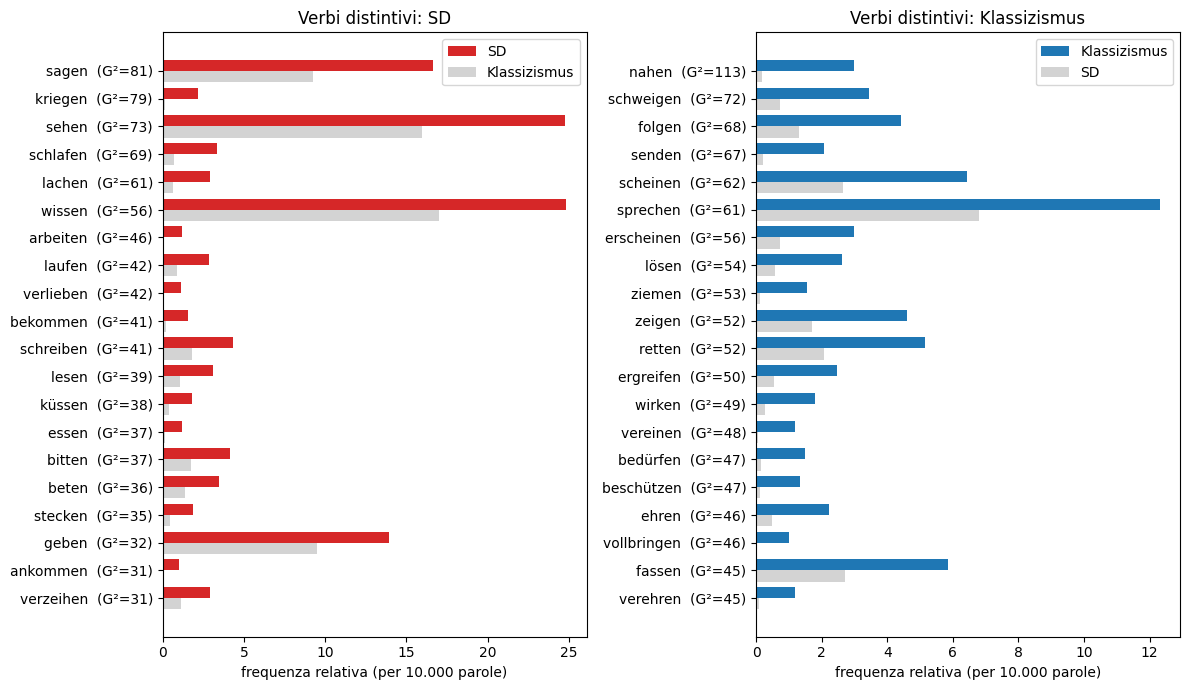

Salvato: /Users/rebeccazani/Desktop/Project work/GerDraCor SD Klassizismus/risultati_frequenza/verbi_distintivi.csv


,classe,conteggio_SD,conteggio_Klassizismus,f_SD x10k,f_Klassizismus x10k,log2_ratio,G2,controlli superati (su 4),verdetto,quota_verbo,forme principali
sagen,SD,629,355,16.64,9.26,0.84,81.22,4,A robusta,1.00,"sagen (723), sage (148), sagst (91), sagten (23)"
kriegen,SD,82,6,2.17,0.16,3.69,79.26,4,A robusta,0.98,"kriegen (35), kriegt (27), kriegte (8), gekrie..."
sehen,SD,936,611,24.77,15.94,0.64,73.44,4,B solida ma sensibile,0.87,"sehen (458), sieh (309), sieht (252), sehe (14..."
schlafen,SD,126,28,3.33,0.73,2.17,68.84,4,A robusta,0.97,"schlafen (97), schläft (42), geschlafen (12), ..."
lachen,SD,110,24,2.91,0.63,2.19,61.01,4,A robusta,0.84,"lachen (87), lacht (27), lachte (12), lache (3..."
...,...,...,...,...,...,...,...,...,...,...,...
vollenden,Klassizismus,8,52,0.21,1.36,-2.61,-35.44,4,,0.93,"vollenden (30), vollendet (29), vollende (1)"
erheben,Klassizismus,23,83,0.61,2.17,-1.81,-35.22,4,,0.99,"erheben (47), erhebt (34), erhoben (10), erheb..."
gebieten,Klassizismus,2,34,0.05,0.89,-3.77,-34.01,3,,1.00,"gebietet (19), gebieten (14), geboten (2), geb..."
täuschen,Klassizismus,3,37,0.08,0.97,-3.40,-33.66,3,,1.00,"täuschen (16), getäuscht (15), täuschte (4), t..."


In [25]:
QUOTA_VERBO = CFG["verbi"]["quota_verbo"]      # un lemma è un verbo se almeno questa quota delle sue occorrenze è taggata VERB
TOP_N_VERBI = CFG["verbi"]["top_n_verbi"]      # quanti verbi distintivi mostrare per classe
PSEUDO = CFG["distintive"]["pseudo_pesi_uguali"]

# Categoria più frequente di ogni lemma e quota di occorrenze taggate VERB (dati raccolti in 4a)
freq["pos_principale"] = [pos_del_lemma[w].most_common(1)[0][0] if w in pos_del_lemma else "" for w in freq.index]
freq["quota_verbo"] = [pos_del_lemma[w]["VERB"] / sum(pos_del_lemma[w].values()) if w in pos_del_lemma else 0.0
                       for w in freq.index]
e_verbo = freq["quota_verbo"] >= QUOTA_VERBO

# Bonferroni calcolata solo sui verbi testabili (soglia più bassa di quella per tutte le parole)
n_verbi_testati = int((e_verbo.to_numpy() & da_testare).sum())
G2_BONF_VERBI = chi2.isf(0.05 / max(n_verbi_testati, 1), df=1)
print(f"{int(e_verbo.sum()):,} lemmi su {len(freq):,} sono verbi (quota VERB >= {QUOTA_VERBO:.0%}); "
      f"{n_verbi_testati:,} hanno almeno {MIN_COUNT} occorrenze")
print(f"Soglia G² di Bonferroni per i soli verbi: {G2_BONF_VERBI:.1f}  (per tutte le parole era {G2_BONF:.1f})\n")


def verbi_distintivi(classe, top_n=TOP_N_VERBI):
    """I primi top_n verbi distintivi di una classe: stessi filtri della sezione 6, ma solo sui verbi."""
    segno = 1 if classe == "SD" else -1          # +1 SD, -1 Klassizismus
    scelti = freq[e_verbo
                  & (freq[f"conteggio_{classe}"] >= MIN_COUNT)
                  & (freq[f"opere_{classe}"] >= MIN_OPERE)
                  & (segno * freq["log2_ratio"] >= MIN_LOG2)
                  & (segno * freq["G2"] > G2_BONF_VERBI)]
    return scelti.sort_values("G2", ascending=(classe != "SD")).head(top_n)


verbi_SD, verbi_K = verbi_distintivi("SD"), verbi_distintivi("Klassizismus")

CONTROLLI_RAPIDI = ["regge per opera", "concorda a pesi uguali", "concorda in ogni autore", "regge log-odds"]


def controlli_rapidi(tab, classe):
    """I quattro controlli rapidi (come nelle sezioni 6b, 7a, 7b) per i verbi di una tabella."""
    segno = 1 if classe == "SD" else -1
    parole = list(tab.index)
    px = freq.index.get_indexer(parole)           # posizione dei verbi nella matrice
    out = pd.DataFrame(index=parole)

    # 1. regge per opera (q < 0,05 e segno giusto)
    out["r_opere"] = per_opera["r_opere"].reindex(parole)
    out["q_opere"] = per_opera["q_opere"].reindex(parole)
    out["regge per opera"] = (out["q_opere"] < 0.05) & (segno * out["r_opere"] > 0)

    # 2. concorda a pesi uguali per opera
    m_sd = frequenza_opera[opera_sd][:, px].mean(0)
    m_k = frequenza_opera[~opera_sd][:, px].mean(0)
    out["log2 pesi uguali"] = np.log2((m_sd + PSEUDO) / (m_k + PSEUDO))
    out["concorda a pesi uguali"] = segno * out["log2 pesi uguali"] >= MIN_LOG2

    # 3. concorda dentro ogni autore condiviso (passa anche se l'autore usa il verbo troppo poco per giudicare)
    ok_aut = np.ones(len(parole), dtype=bool)
    for aut in autori_condivisi:
        i_sd = [i for i, o in enumerate(opere) if autore_di[o] == aut and classe_di[o] == "SD"]
        i_k = [i for i, o in enumerate(opere) if autore_di[o] == aut and classe_di[o] == "Klassizismus"]
        cs, ck = X[i_sd].sum(0)[px], X[i_k].sum(0)[px]
        l2 = np.log2(((cs + 0.5) / parole_opera[i_sd].sum()) / ((ck + 0.5) / parole_opera[i_k].sum()))
        ok_aut &= (np.sign(l2) * segno > 0) | ((cs + ck) < MIN_OCC_AUTORE)
    out["concorda in ogni autore"] = ok_aut

    # 4. regge con i log-odds
    out["regge log-odds"] = (segno * tab["z_logodds"]) > Z_SOGLIA

    out["controlli superati (su 4)"] = out[CONTROLLI_RAPIDI].sum(axis=1)
    return out


def tabella_verbi(tab, classe):
    """Tabella completa dei verbi di una classe."""
    t = tab[["conteggio_SD", "conteggio_Klassizismus", "f_SD x10k", "f_Klassizismus x10k", "log2_ratio", "G2", "z_logodds",
             "opere_SD", "opere_Klassizismus", "quota_verbo"]].join(controlli_rapidi(tab, classe))
    t.insert(0, "classe", classe)
    t["verdetto"] = controlli["verdetto"].reindex(t.index).fillna("")     # solo per i verbi tra le prime TOP_N parole distintive
    t["forme principali"] = [", ".join(f"{f} ({n})" for f, n in forme_del_lemma[w].most_common(5)) for w in t.index]
    return t


tab_verbi = pd.concat([tabella_verbi(verbi_SD, "SD"), tabella_verbi(verbi_K, "Klassizismus")])

# Riepilogo per classe
for c in classi:
    t = tab_verbi[tab_verbi["classe"] == c]
    solidi = t.index[t["controlli superati (su 4)"] == 4]
    riserve = t[t["controlli superati (su 4)"] < 4]
    print(f"{c}: {len(t)} verbi distintivi, {len(solidi)} superano tutti e 4 i controlli rapidi")
    print("   solidi:      ", ", ".join(solidi) or "nessuno")
    print("   con riserve: ", "; ".join(f"{w} (non: {', '.join(col for col in CONTROLLI_RAPIDI if not r[col])})"
                                       for w, r in riserve.iterrows()) or "nessuno", "\n")

# Parole distintive della sezione 6 che sono verbo solo in parte (omonimie verbo/nome o errori del tagger)
ambigui = [w for w in candidate if 0.2 <= freq.loc[w, "quota_verbo"] < QUOTA_VERBO]
print("Parole distintive della sezione 6 che sono verbo solo in parte (omonimie verbo/nome o errori del tagger):")
print("  ", ", ".join(f"{w} ({freq.loc[w, 'quota_verbo']:.0%} verbo)" for w in ambigui) or "nessuna")

# Grafico: i primi 20 verbi per classe
fig, assi = plt.subplots(1, 2, figsize=(12, 7))
for ax, (c, tab, colore) in zip(assi, [("SD", verbi_SD, "tab:red"), ("Klassizismus", verbi_K, "tab:blue")]):
    altra = "Klassizismus" if c == "SD" else "SD"
    top = tab.head(20)
    y = np.arange(len(top))[::-1]
    ax.barh(y + 0.2, top[f"f_{c} x10k"], height=0.4, color=colore, label=c)
    ax.barh(y - 0.2, top[f"f_{altra} x10k"], height=0.4, color="lightgray", label=altra)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{w}  (G²={abs(g):.0f})" for w, g in zip(top.index, top["G2"])])
    ax.set_xlabel("frequenza relativa (per 10.000 parole)")
    ax.set_title(f"Verbi distintivi: {c}")
    ax.legend()
plt.tight_layout()
plt.show()

# Salvataggio
Path(CARTELLA_OUT).mkdir(parents=True, exist_ok=True)
tab_verbi.to_csv(Path(CARTELLA_OUT) / "verbi_distintivi.csv", encoding="utf-8-sig")
print("Salvato:", Path(CARTELLA_OUT) / "verbi_distintivi.csv")

tab_verbi[["classe", "conteggio_SD", "conteggio_Klassizismus", "f_SD x10k", "f_Klassizismus x10k", "log2_ratio", "G2",
           "controlli superati (su 4)", "verdetto", "quota_verbo", "forme principali"]].round(2)

In [26]:
# verbi modali: tolti dall'analisi principale (spaCy li tagga AUX), controllati qui a parte
# Qui si contano le forme direttamente nel testo; le frequenze sono per 10.000 parole del TESTO (non delle sole parole utili).
# Dizionario 'verbo modale -> tutte le sue forme' (con grafie antiche, es. muß/muss).
# Si contano a parte perché spaCy li classifica come ausiliari e l'analisi principale li ha tolti.
MODALI = {
    # können (potere/sapere).
    "können": ["kann", "kannst", "können", "könnt", "konnte", "konntest", "konnten", "könnte", "könntest", "könnten", "gekonnt"],
    # müssen (dovere, necessità).
    "müssen": ["muss", "muß", "musst", "mußt", "müssen", "müsst", "müßt", "musste", "mußte", "musstest", "mußtest",
               # (prosegue)
               "mussten", "mußten", "müsste", "müßte", "müssten", "müßten", "gemusst", "gemußt"],
    # sollen (dovere, obbligo).
    "sollen": ["soll", "sollst", "sollen", "sollt", "sollte", "solltest", "sollten", "gesollt"],
    # wollen (volere).
    "wollen": ["will", "willst", "wollen", "wollt", "wollte", "wolltest", "wollten", "gewollt"],
    # dürfen (essere permesso).
    "dürfen": ["darf", "darfst", "dürfen", "dürft", "durfte", "durftest", "durften", "dürfte", "dürftest", "dürften", "gedurft"],
    # mögen (piacere/potere).
    "mögen":  ["mag", "magst", "mögen", "mögt", "mochte", "mochtest", "mochten", "möchte", "möchtest", "möchten", "gemocht"],
}
# Dizionario inverso 'forma -> verbo modale': posso così riconoscere ogni forma nel testo.
forma_a_modale = {f: m for m, fs in MODALI.items() for f in fs}
# Contatori per opera dei modali.
cnt_modali = {o: Counter() for o in opere}
# Parole totali del testo per opera, ricontate qui.
tot_testo = {o: 0 for o in opere}
# Per ogni opera...
for o in opere:
    # ...ogni battuta...
    for battuta in tei[o]["battute"]:
        # ...ogni parola;
        for w in re.findall(r"[^\W\d_]+", sistema_elisioni(battuta)):
            # la conto nel totale;
            tot_testo[o] += 1
            # se è una forma di un modale...
            m = forma_a_modale.get(w.lower())
            # (controllo)
            if m:
                # ...la conto per quel modale.
                cnt_modali[o][m] += 1

# Controllo di coerenza: questi totali devono coincidere con il denominatore unico usato altrove.
if any(tot_testo[o] != p for o, p in zip(opere, parole_opera)):
    # Se non coincidono, avviso.
    print("ATTENZIONE: il conteggio delle parole dei modali non coincide con il denominatore unico")
# Parole totali del testo per classe.
n_testo = {c: sum(tot_testo[o] for o in opere if classe_di[o] == c) for c in classi}
# Righe della tabella dei modali.
righe_m = []
# Per ogni modale...
for m in MODALI:
    # ...conteggio in SD;
    a_ = sum(cnt_modali[o][m] for o in opere if classe_di[o] == "SD")
    # conteggio in Klassizismus;
    b_ = sum(cnt_modali[o][m] for o in opere if classe_di[o] == "Klassizismus")
    # frequenza per 10.000 parole in ogni opera;
    fo = np.array([cnt_modali[o][m] / tot_testo[o] * 1e4 for o in opere])
    # test di Mann-Whitney fra opere SD e Klassizismus;
    U_m, p_m = mannwhitneyu(fo[opera_sd], fo[~opera_sd], alternative="two-sided")
    # registro: conteggi, frequenze per 10.000 parole,
    righe_m.append({"modale": m, "conteggio_SD": a_, "conteggio_Klassizismus": b_,
                    # (prosegue)
                    "f_SD x10k": a_ / n_testo["SD"] * 1e4, "f_Klassizismus x10k": b_ / n_testo["Klassizismus"] * 1e4,
                    # log2 ratio,
                    "log2_ratio": np.log2(((a_ + 0.5) / n_testo["SD"]) / ((b_ + 0.5) / n_testo["Klassizismus"])),
                    # G²,
                    "G2": float(g2(a_, b_, n_testo["SD"], n_testo["Klassizismus"])),
                    # effetto r e p-value.
                    "r_opere": 2 * U_m / (opera_sd.sum() * (~opera_sd).sum()) - 1, "p_opere": p_m})
# Tabella dei modali.
tab_modali = pd.DataFrame(righe_m).set_index("modale")
# Correggo i p-value per confronti multipli.
tab_modali["q_opere"] = multipletests(tab_modali["p_opere"], method="fdr_bh")[1]
# Stampo come leggere la tabella. Con soli 6 test, |G²| > 10,83 è una soglia indicativa sufficiente.
print("Verbi modali (positivo = più frequente nello SD, negativo = nella Klassizismus). Con 6 verbi testati |G²| > 10,83 basta come soglia indicativa.")
# Salvo in CSV.
tab_modali.to_csv(Path(CARTELLA_OUT) / "verbi_modali.csv", encoding="utf-8-sig")
# Mostro la tabella, arrotondata.
tab_modali.round(3)

Verbi modali (positivo = più frequente nello SD, negativo = nella Klassizismus). Con 6 verbi testati |G²| > 10,83 basta come soglia indicativa.


,conteggio_SD,conteggio_Klassizismus,f_SD x10k,f_Klassizismus x10k,log2_ratio,G2,r_opere,p_opere,q_opere
modale,,,,,,,,,
können,2109,1642,55.801,42.838,0.381,65.052,0.505,0.007,0.011
müssen,1363,962,36.063,25.097,0.523,75.269,0.668,0.000,0.001
sollen,1838,1409,48.631,36.759,0.404,63.046,0.558,0.003,0.006
wollen,2935,1644,77.656,42.890,0.856,387.366,0.868,0.000,0.000
dürfen,233,371,6.165,9.679,-0.650,-29.897,-0.432,0.022,0.026
mögen,427,433,11.298,11.296,0.000,0.000,0.132,0.491,0.491


## 11c. Contesto di ogni parola distintiva

Per ogni parola (verbi compresi) questa sezione mostra:

- **forme**: quali forme del testo sono confluite nel lemma, separatamente per classe (es. *sieh, siehst* contro *sehet*), che dicono qualcosa su persona, tempo e imperativo;
- **vicini frequenti**: i lemmi che stanno più spesso nelle `FINESTRA_COLL` parole prima o dopo (3 + 3);
- **vicini specifici**: gli stessi lemmi, ma ordinati per quanto compaiono *più spesso di quanto farebbe il caso* (misura *local MI*: conteggio × log₂(osservato / atteso)). I vicini frequenti sono dominati da parole comuni (*kommen*, *sagen*), i vicini specifici mostrano le vere associazioni (*gnädig* + *Herr*);
- **frasi di esempio**: fino a `N_ESEMPI` per classe, prese a caso ma da **opere diverse** (così un'opera sola non domina), con la parola tra [parentesi quadre].

Tutto è mostrato **per entrambe le classi**, anche per una parola tipica dello SD: vedere come la stessa parola si comporta nella Klassizismus è spesso la parte più istruttiva (*Herr* in *Herr Gott* contro *gnädiger Herr*).

Nota: il testo mostrato ha la stessa normalizzazione dell'analisi (elisioni ricomposte, *th* > *t*, *ey* > *ei*); i nomi dei personaggi e le parole scartate (stopword, pronomi...) non compaiono tra i vicini. Per i vicini grezzi, comprese le parole grammaticali, resta `collocati` della sezione 4c.

`scheda("lemma")` stampa la scheda di una parola; `tabella_contesti(lista)` produce una tabella con una riga per parola, che viene salvata in CSV ed Excel.

In [27]:
FINESTRA = CFG["contesti"]["finestra_coll"]
N_COLL = CFG["contesti"]["n_coll"]
N_ESEMPI = CFG["contesti"]["n_esempi"]
LARGH = CFG["contesti"]["larghezza_esempio"]

PAROLA_RE = re.compile(r"[^\W\d_]+")
escluse = set(frammenti_esclusi) if "frammenti_esclusi" in globals() else set()

# Una riga per battuta: (opera, testo normalizzato, [(parola minuscola, inizio, fine), ...])
RIGHE = []
for opera, dati in tei.items():
    if opera in opere:                       # 'opere' = elenco delle opere nell'analisi (sezione 5)
        for battuta in dati["battute"]:
            t = PAROLA_RE.sub(lambda m: normalizza_parola(m.group(0)), sistema_elisioni(battuta))
            RIGHE.append((opera, t, [(m.group(0).lower(), m.start(), m.end()) for m in PAROLA_RE.finditer(t)]))
print(f"{len(RIGHE):,} battute pronte")


def contesti(lemma):
    """Per un lemma e per ciascuna classe: forme, vicini frequenti ed esempi."""
    forme_lemma = set(forme_del_lemma.get(lemma, {}))
    out = {c: {"n": 0, "forme": Counter(), "vicini": Counter(), "esempi": []} for c in classi}
    rng = np.random.default_rng(0)
    for opera, t, toks in RIGHE:
        s = out[classe_di[opera]]
        parole = [w for w, _, _ in toks]
        for i, w in enumerate(parole):
            if w in forme_lemma:
                s["n"] += 1
                s["forme"][w] += 1
                for j in range(max(0, i - FINESTRA), min(len(parole), i + FINESTRA + 1)):
                    if j != i and parole[j] not in forme_lemma:
                        s["vicini"][parole[j]] += 1
                s["esempi"].append((opera, t, toks[i]))
    for s in out.values():
        scelti = rng.permutation(len(s["esempi"]))[:N_ESEMPI]
        s["esempi"] = [s["esempi"][k] for k in scelti]
    return out


def scheda(lemma):
    if lemma not in freq.index:
        return print(f"'{lemma}' non è nel vocabolario")
    ctx = contesti(lemma)
    riga = freq.loc[lemma]
    print("=" * 90)
    print(f"{lemma.upper()}   G² = {riga['G2']:+.1f}  ({'tipica SD' if riga['G2'] > 0 else 'tipica Klassizismus'})")
    for c in classi:
        s = ctx[c]
        print(f"\n  {c}: {s['n']} occorrenze")
        print("    forme:  ", ", ".join(f"{f} ({n})" for f, n in s["forme"].most_common(6)) or "-")
        print("    vicini: ", ", ".join(f"{v} ({n})" for v, n in s["vicini"].most_common(N_COLL)) or "-")
        for opera, t, (_, a, b) in s["esempi"]:
            frase = re.sub(r"\s+", " ", f"…{t[max(0, a - LARGH):a]}[{t[a:b]}]{t[b:b + LARGH]}…")
            print(f"      · [{opera[:24]}] {frase}")
    print()


for w in ["herr", "kopf", "könig"]:
    scheda(w)

28,191 battute pronte
HERR   G² = +299.1  (tipica SD)

  SD: 1170 occorrenze
    forme:   herr (916), herrn (189), herren (65)
    vicini:  sie (227), ich (198), der (163), mein (123), und (116), gnädiger (87), nicht (85), ist (84)
      · [lenz-der-hofmeister] …und Kirchenraub Kirchenraub – Ich will ihm einen Brief schreiben, dem [Herrn] Major, den er nicht ins Fenster stecken soll.…
      · [leisewitz-julius-von-tar] …Für den Prinzen nicht, aber für Sie! – Kommen Sie, gnädiger [Herr].…
      · [wagner-die-kindermoerder] …»Mein [Herr]! Sie heißen Humbrecht, und mögen leicht mehr Verstand haben, als alle…

  Klassizismus: 490 occorrenze
    forme:   herr (302), herrn (153), herren (35)
    vicini:  der (88), und (63), ich (58), ihr (57), ist (47), nicht (45), die (41), mein (37)
      · [schiller-maria-stuart] …l, Bei Ihro Majestät mich einzuführen, Daß ich den Glückwunsch meines [Herrn] und Königs Zu ihren Füßen schuldigst niederlege –…
      · [goethe-egmont] …Freilich! – Unsere Vorf

In [32]:
# Schede di esempio: i primi tre verbi di ciascuna classe e "herr"
da_mostrare = list(verbi_SD.index[:3]) + list(verbi_K.index[:3]) + ["herr"]
for w in da_mostrare:
    scheda(w)
# Per un'altra parola: scheda("nome_del_lemma")

SAGEN   G² = +81.2  (tipica SD)

  SD: 641 occorrenze
    forme:   sagen (491), sage (91), sagst (40), sagten (19)
    vicini:  ich (266), sie (154), es (112), zu (100), du (97), was (88), mir (83), dir (71)
      · [klinger-sturm-und-drang] …Ja Mylord, eine Bitte an Sie. Wollen Sie uns wohl [sagen] den wahren Namen Ihres Begleiters, des Wilds!…
      · [wagner-die-kindermoerder] …nblick mit so viel Bitterkeit vorwarfen, bin es ich Ihnen schuldig zu [sagen], und Ihre Pflicht ist es, nichts ununtersucht zu lassen. Sehn Sie, di…
      · [schiller-die-verschwoeru] …t – es selbst aufzufressen. – Aber genug. Nur im Vorbeigehen, Herzog, [sage] mir, was verbrach denn der arme Teufel, den ihr am Jesuiterdom aufknü…

  Klassizismus: 386 occorrenze
    forme:   sagen (231), sage (98), sagst (52), sagten (5)
    vicini:  ich (125), du (80), was (79), zu (78), mir (74), es (54), sie (44), nicht (43)
      · [seume-miltiades] …l; Dort nehmt Ersatz, und Glück und Unglück kommt Ins Gleiche wieder! [S

In [33]:
# Tabella con il contesto di tutte le parole distintive (sezione 6 + verbi della 11b)
PAROLE_CONTESTO = list(dict.fromkeys(list(candidate) + (list(verbi_SD.index) + list(verbi_K.index) if "verbi_SD" in globals() else [])))
# Per aggiungerne altre: PAROLE_CONTESTO += ["wetter", "pflicht"]


def tabella_contesti(parole):
    """Una riga per parola: forme, vicini ed esempi per classe (usa contesti() della 11c, un lemma alla volta)."""
    righe = []
    for w in dict.fromkeys(parole):
        if w not in freq.index:
            continue
        ctx = contesti(w)
        r = {"lemma": w,
             "tipica di": "SD" if freq.loc[w, "G2"] > 0 else "Klassizismus",
             "pos": freq.loc[w].get("pos_principale", ""),
             "G2": freq.loc[w, "G2"], "log2_ratio": freq.loc[w, "log2_ratio"]}
        for c in classi:
            s = ctx[c]
            r[f"occorrenze {c}"] = s["n"]
            r[f"forme {c}"] = ", ".join(f"{f} ({n})" for f, n in s["forme"].most_common(6))
            r[f"vicini {c}"] = ", ".join(f"{v} ({n})" for v, n in s["vicini"].most_common(N_COLL))
            for k in range(N_ESEMPI):
                if k < len(s["esempi"]):
                    opera, t, (_, a, b) = s["esempi"][k]
                    frase = re.sub(r"\s+", " ", f"…{t[max(0, a - LARGH):a]}[{t[a:b]}]{t[b:b + LARGH]}…")
                    r[f"esempio {k + 1} {c}"] = f"[{opera[:24]}] {frase}"
                else:
                    r[f"esempio {k + 1} {c}"] = ""
        righe.append(r)
    return pd.DataFrame(righe).set_index("lemma")


tab_contesti = tabella_contesti(PAROLE_CONTESTO)
Path(CARTELLA_OUT).mkdir(parents=True, exist_ok=True)
tab_contesti.to_csv(Path(CARTELLA_OUT) / "contesti_parole_distintive.csv", encoding="utf-8-sig")
try:
    tab_contesti.to_excel(Path(CARTELLA_OUT) / "contesti_parole_distintive.xlsx")
except Exception as errore:
    print("Excel non salvato (resta il CSV):", errore)
print(f"{len(tab_contesti)} parole, salvate in {Path(CARTELLA_OUT)}/contesti_parole_distintive.csv (.xlsx)")

tab_contesti[["tipica di", "pos", "G2", "occorrenze SD", "occorrenze Klassizismus",
              "vicini SD", "vicini Klassizismus"]].round(1)

162 parole, salvate in /Users/rebeccazani/Desktop/Project work/GerDraCor SD Klassizismus/risultati_frequenza/contesti_parole_distintive.csv (.xlsx)


,tipica di,pos,G2,occorrenze SD,occorrenze Klassizismus,vicini SD,vicini Klassizismus
lemma,,,,,,,
herr,SD,NOUN,299.1,1170,490,"sie (227), ich (198), der (163), mein (123), u...","der (88), und (63), ich (58), ihr (57), ist (4..."
junge,SD,NOUN,132.0,214,44,"der (51), ich (30), den (22), ein (20), die (1...","der (11), die (9), das (8), den (7), in (6), s..."
kopf,SD,NOUN,124.8,241,59,"den (81), und (33), in (32), der (31), die (30...","und (10), der (9), die (9), den (9), nicht (8)..."
kerl,SD,NOUN,101.5,165,16,"ein (54), der (42), die (29), ich (20), den (1...","ein (6), der (6), ist (4), sie (3), und (2), d..."
mädchen,SD,NOUN,95.2,245,76,"das (77), ein (57), und (34), ist (33), ich (3...","das (21), ein (17), du (14), ich (12), und (10..."
...,...,...,...,...,...,...,...
vollenden,Klassizismus,VERB,-35.4,9,69,"und (3), werk (2), der (2), zu (2), geh (1), w...","es (12), ich (11), und (11), das (9), werk (8)..."
erheben,Klassizismus,VERB,-35.2,23,92,"zu (9), und (5), den (4), sich (4), über (3), ...","sich (36), die (19), der (16), zu (14), und (1..."
gebieten,Klassizismus,VERB,-34.0,6,57,"sei (4), trotz (3), die (2), eurem (1), grimme...","mir (10), und (9), zu (9), der (7), die (6), e..."


## 11d. Distanza di stile tra le opere: Burrows' Delta

Finora abbiamo cercato le parole che distinguono le due classi. Qui facciamo la domanda opposta, senza partire dalle etichette: **quali opere si assomigliano di più nell'uso delle parole più frequenti?** E le opere vicine sono dello stesso autore, della stessa classe, o di nessuno dei due?

**Come funziona Burrows' Delta**

1. Si prendono i `N_MFW` lemmi più frequenti dell'intero corpus (*most frequent words*).
2. Per ogni opera si calcola la frequenza relativa di ciascuno (conteggio diviso per le parole del testo dell'opera).
3. Si standardizza ogni lemma (**z-score**): si toglie la media tra le opere e si divide per la deviazione standard. Così un lemma molto frequente non pesa più di uno meno frequente.
4. Il **Delta** tra due opere è la media delle differenze assolute dei loro z-score: più è piccolo, più le due opere usano quei lemmi con proporzioni simili.
5. Le opere si raggruppano con un **dendrogramma** (clustering gerarchico, legame medio).

**Limite da dichiarare.** Il Delta classico lavora sulle parole grammaticali, che qui sono già state scartate (sezione 4). Questa è quindi una variante sui lemmi di contenuto più frequenti.

**Controllo numerico.** Per ogni opera si guarda l'opera più vicina: (a) è dello stesso autore? (b) escluse le opere dello stesso autore, è della stessa classe? Il confronto (b) va letto accanto al valore che si avrebbe per caso. Si ripete per più valori di `N_MFW`, per vedere se il risultato dipende da questa scelta.

In [35]:
# Burrows' Delta: distanza di stile tra le opere, sui lemmi più frequenti del corpus.
N_MFW = 200                     # lemmi più frequenti usati per grafico e tabella principale
N_PROVE = [100, 200, 300, 500]  # altri valori, per controllare che il risultato non dipenda dalla scelta

aut_arr = np.array([autore_di[o] for o in opere])   # autore di ogni opera (stesso ordine delle righe di X)
cl_arr = np.array([classe_di[o] for o in opere])    # classe di ogni opera


def delta_burrows(n_mfw):
    """Tabella opere × opere dei Delta, sui n_mfw lemmi più frequenti."""
    top = np.argsort(-X.sum(axis=0))[:n_mfw]
    F = X[:, top] / parole_opera[:, None]                    # frequenze relative per opera
    Zs = (F - F.mean(axis=0)) / F.std(axis=0, ddof=1)        # z-score: ogni lemma pesa uguale
    return np.abs(Zs[:, None, :] - Zs[None, :, :]).mean(axis=2)


def vicini_piu_prossimi(D):
    """Quote di opere con vicino più prossimo dello stesso autore / di altro autore ma stessa classe, e quota attesa per caso."""
    D1 = D.astype(float).copy()
    np.fill_diagonal(D1, np.inf)

    # (a) vicino più prossimo: è dello stesso autore? (solo per autori con almeno 2 opere)
    ha_altre = np.array([(aut_arr == a).sum() > 1 for a in aut_arr])
    stesso_aut = (aut_arr[D1.argmin(axis=1)] == aut_arr)[ha_altre].mean()

    # (b) escludo lo stesso autore: la classe conta anche tra autori diversi?
    D2 = D1.copy()
    D2[aut_arr[:, None] == aut_arr[None, :]] = np.inf
    stessa_classe = (cl_arr[D2.argmin(axis=1)] == cl_arr).mean()

    # Valore atteso per caso
    caso = np.mean([(cl_arr[aut_arr != aut_arr[i]] == cl_arr[i]).mean() for i in range(len(opere))])
    return stesso_aut, stessa_classe, caso


# Controllo per i diversi N
righe = []
for n in N_PROVE:
    a, b, c = vicini_piu_prossimi(delta_burrows(n))
    righe.append({"N_MFW": n, "vicino dello stesso autore": a,
                  "vicino di altro autore, stessa classe": b, "stessa classe per caso": c})
delta_controllo = pd.DataFrame(righe).set_index("N_MFW")
print((delta_controllo * 100).round(1).to_string())
print("\nQuote in % di opere. La seconda colonna va confrontata con la terza (valore atteso per caso).")

# Delta per il valore principale (serve al dendrogramma) e salvataggio
DELTA = delta_burrows(N_MFW)
Path(CARTELLA_OUT).mkdir(parents=True, exist_ok=True)
pd.DataFrame(DELTA, index=opere, columns=opere).to_csv(Path(CARTELLA_OUT) / "delta_distanze.csv", encoding="utf-8-sig")
delta_controllo.to_csv(Path(CARTELLA_OUT) / "delta_controllo.csv", encoding="utf-8-sig")

       vicino dello stesso autore  vicino di altro autore, stessa classe  stessa classe per caso
N_MFW                                                                                           
100                          53.1                                   79.5                    47.4
200                          68.8                                   84.6                    47.4
300                          78.1                                   92.3                    47.4
500                          78.1                                   94.9                    47.4

Quote in % di opere. La seconda colonna va confrontata con la terza (valore atteso per caso).


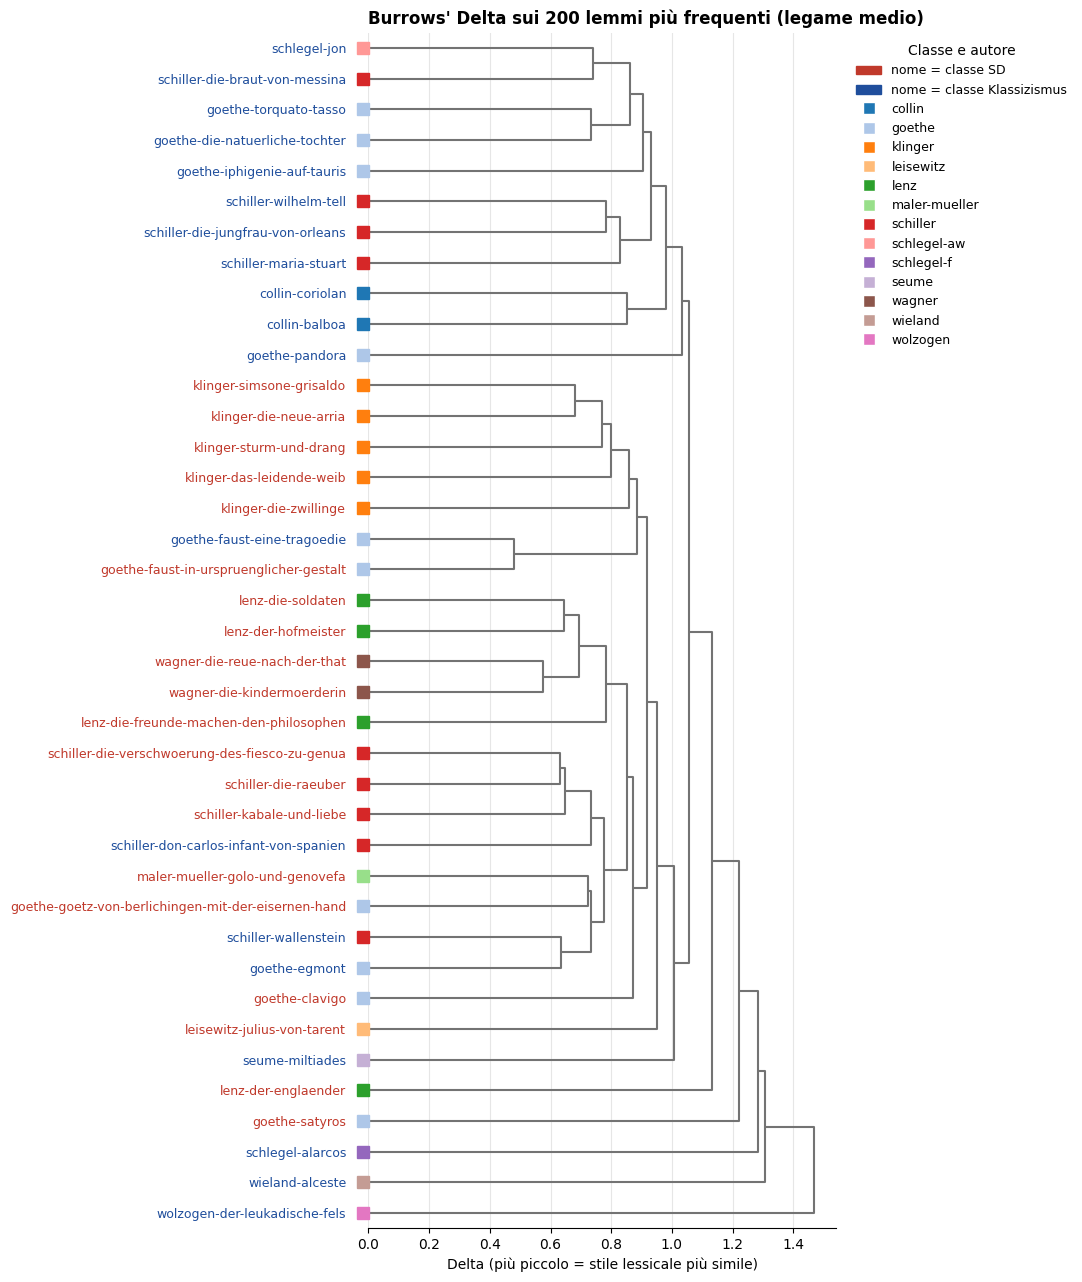

In [37]:
# Dendrogramma delle opere: opere vicine = stile lessicale simile.
# Colore del nome = classe; quadratino = autore.
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Albero gerarchico con legame medio
albero = linkage(squareform(DELTA, checks=False), method="average")

col_classe = {"SD": "#c0392b", "Klassizismus": "#1f4e9c"}
autori_ord = sorted(set(aut_arr))
col_autore = {a: plt.get_cmap("tab20")(i % 20) for i, a in enumerate(autori_ord)}   # % 20: regge anche più di 20 autori

fig, ax = plt.subplots(figsize=(11, 0.28 * len(opere) + 2))
dendrogram(albero, labels=opere, orientation="right", ax=ax,
           color_threshold=0, above_threshold_color="0.45", leaf_font_size=9)

# Nomi colorati per classe, con accanto il quadratino dell'autore
ax.tick_params(axis="y", pad=16, length=0)
for t in ax.get_ymajorticklabels():
    o = t.get_text()
    t.set_color(col_classe[classe_di[o]])
    ax.plot([-0.012], [t.get_position()[1]], marker="s", markersize=8, color=col_autore[autore_di[o]],
            transform=ax.get_yaxis_transform(), clip_on=False, linestyle="none")

ax.set_title(f"Burrows' Delta sui {N_MFW} lemmi più frequenti (legame medio)", loc="left", fontweight="bold")
ax.set_xlabel("Delta (più piccolo = stile lessicale più simile)")
ax.grid(axis="x", color="0.9", linewidth=0.8)
ax.set_axisbelow(True)
for lato in ("top", "right", "left"):
    ax.spines[lato].set_visible(False)

# Legenda fuori dal grafico: classi (testo colorato), poi autori (quadratini)
voci = [Patch(color=col_classe[c], label=f"nome = classe {c}") for c in classi]
voci += [Line2D([0], [0], marker="s", color="w", markerfacecolor=col_autore[a], markersize=9, label=a)
         for a in autori_ord]
ax.legend(handles=voci, loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False, fontsize=9,
          title="Classe e autore", title_fontsize=10)

plt.tight_layout()
plt.savefig(Path(CARTELLA_OUT) / "delta_dendrogramma.png", dpi=200, bbox_inches="tight")
plt.show()

## 12. Salvataggio

Le tabelle vengono salvate come file CSV in `CARTELLA_OUT` (si aprono con Excel). La più importante è `tabella_finale.csv`.

In [39]:
out = Path(CARTELLA_OUT)
out.mkdir(parents=True, exist_ok=True)

def salva(nome_file, costruisci, indice=True):
    """Salva un CSV; se una variabile manca o dà errore, salta e lo annota."""
    try:
        costruisci().to_csv(out / nome_file, index=indice, encoding="utf-8-sig")
        salvati.append(nome_file)
    except Exception as e:
        saltati.append(f"{nome_file}  ({type(e).__name__}: {e})")

salvati, saltati = [], []

salva("frequenze_relative.csv",              lambda: freq.sort_values("G2", ascending=False))
salva("distintive_SD.csv",                   lambda: distintive_SD[colonne])
salva("distintive_Klassizismus.csv",         lambda: distintive_K[colonne])
salva("tabella_finale.csv",                  lambda: tabella_finale)
salva("test_per_opera.csv",                  lambda: per_opera)
salva("leave_one_author_out.csv",            lambda: LOAO)
salva("posizione_drammi_asse_lessicale.csv", lambda: asse)
salva("lemmi_riparati.csv",                  lambda: pd.Series(RIPARA, name="forma_piena"))
salva("nomi_tolti.csv",                      lambda: pd.Series(sorted(NOMI), name="nome_tolto"), indice=False)
salva("permutazioni_distribuzioni.csv",      lambda: pd.DataFrame({"opere": casuali_opere, "autori": casuali_autori}), indice=False)
salva("diagnostica_confondimenti.csv",       lambda: diag)
salva("asse_lessicale_auc.csv",              lambda: auc_tab)
salva("normalizzazioni_ortografiche.csv",    lambda: audit_orto, indice=False)
salva("confronto_liste.csv",                 lambda: confronto_liste)
salva("delta_distanze.csv",                  lambda: pd.DataFrame(DELTA, index=opere, columns=opere))
salva("delta_controllo.csv",                 lambda: delta_controllo)
if "campo_di" in globals() and campo_di:
    salva("campi_semantici.csv",             lambda: pd.Series(campo_di, name="campo").sort_values())
    salva("campi_semantici_pesi.csv",        lambda: campi_tab)

print(f"Salvati {len(salvati)} file in {out.resolve()}")
if saltati:
    print("\nSaltati (variabile mancante o errore):")
    for s in saltati:
        print("  -", s)

Salvati 15 file in /Users/rebeccazani/Desktop/Project work/GerDraCor SD Klassizismus/risultati_frequenza

Saltati (variabile mancante o errore):
  - nomi_tolti.csv  (NameError: name 'NOMI' is not defined)
  - diagnostica_confondimenti.csv  (NameError: name 'diag' is not defined)
  - confronto_liste.csv  (NameError: name 'confronto_liste' is not defined)


## 13. Come riportare i risultati

Formulazioni suggerite, coerenti con quanto il disegno permette di concludere:

- «Le parole X, Y, Z sono *distintive del sottocorpus SD* rispetto al sottocorpus Klassizismus»; non «lessico dello Sturm und Drang».
- «La differenza è robusta a: esclusione di una singola opera, di un singolo autore, di gruppi di autori minori; cambio dei parametri; cambio del modello.»
- «Non è controllabile con questo corpus: l'effetto del periodo, della forma (verso/prosa) e dell'edizione, che coincidono con la classe (sezione 7c). L'unico confronto a parità di autore riguarda Goethe e Schiller.»
- Per l'asse lessicale riportare l'AUC **leave-one-author-out** con il suo intervallo, non quella leave-one-work-out.
- Allegare `config_usata.json` e `ambiente.txt`, salvati accanto ai risultati, così l'esecuzione è riproducibile.